
## Los mejores videojuegos del mundo

Este proyecto tiene como objetivo analizar el mercado de videojuegos para identificar patrones que determinen el éxito de un juego y ayudar a planificar estrategias comerciales efectivas para 2017.

Trabajamos para Ice, una tienda online de videojuegos con alcance mundial. Contamos con datos históricos hasta 2016 que incluyen información sobre ventas por región, plataformas, géneros, reseñas de usuarios y críticos, y clasificaciones ESRB.

Al finalizar este análisis, tendremos una comprensión clara de los factores que impulsan el éxito en el mercado de videojuegos, permitiendo tomar decisiones informadas para maximizar las oportunidades comerciales en 2017.

## 1. INICIALIZACIÓN

In [1]:
# Cargar todas las librerías
import pandas as pd
import math
import numpy as np
from scipy import stats as st
import seaborn as sns
from matplotlib import pyplot as plt
import plotly.express as px

## 2. PREPARACION DE DATOS
#### 2.1. Carga de datos 

In [2]:
#cargar los datos
df_games = pd.read_csv('/datasets/games.csv', sep=',', encoding='utf-8', quotechar= '"')

#Información general
print("Informacion general del Data Frame:")
print(df_games.info)

Informacion general del Data Frame:
<bound method DataFrame.info of                                 Name Platform  Year_of_Release         Genre  \
0                         Wii Sports      Wii           2006.0        Sports   
1                  Super Mario Bros.      NES           1985.0      Platform   
2                     Mario Kart Wii      Wii           2008.0        Racing   
3                  Wii Sports Resort      Wii           2009.0        Sports   
4           Pokemon Red/Pokemon Blue       GB           1996.0  Role-Playing   
...                              ...      ...              ...           ...   
16710  Samurai Warriors: Sanada Maru      PS3           2016.0        Action   
16711               LMA Manager 2007     X360           2006.0        Sports   
16712        Haitaka no Psychedelica      PSV           2016.0     Adventure   
16713               Spirits & Spells      GBA           2003.0      Platform   
16714            Winning Post 8 2016      PSV       

#### 2.2.  Exploración inicial

In [3]:
# Imprimir la información general y resumida sobre el DataFrame Games

print("Forma del DataFrame:", df_games.shape)
print()
print("Columnas:", df_games.columns.tolist())
print()
print("Tipos de datos:", df_games.dtypes)
print()

# Verificar valores nulos
print("Valores nulos por columna:")
print()
print(df_games.isnull().sum())
print()

# Verificar duplicados
duplicados = df_games.duplicated().sum()
print(f"filas duplicadas: {duplicados}")


Forma del DataFrame: (16715, 11)

Columnas: ['Name', 'Platform', 'Year_of_Release', 'Genre', 'NA_sales', 'EU_sales', 'JP_sales', 'Other_sales', 'Critic_Score', 'User_Score', 'Rating']

Tipos de datos: Name                object
Platform            object
Year_of_Release    float64
Genre               object
NA_sales           float64
EU_sales           float64
JP_sales           float64
Other_sales        float64
Critic_Score       float64
User_Score          object
Rating              object
dtype: object

Valores nulos por columna:

Name                  2
Platform              0
Year_of_Release     269
Genre                 2
NA_sales              0
EU_sales              0
JP_sales              0
Other_sales           0
Critic_Score       8578
User_Score         6701
Rating             6766
dtype: int64

filas duplicadas: 0


In [4]:
#Muestra del DF
print("Vista del Data Frame:")
display(df_games.head())

Vista del Data Frame:


,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN


#### Observaciones iniciales
- Tenemos tipos de datos incorrectos en la columna de Fecha, ya que son float64, pero deben ser enteros.
- Analizar las columnas con valores ausentes para entender el por qué aparecen y definir si se reemplazan.
- Para el caso de la columna user_score, el tipo de datos deberá ser Float64 para poder realizar los cálculos correspondientes.


#### 2.3.  Correción de los datos

#### 2.3.1. Cambiar nombres de columnas a minúsculas

In [5]:
#Cambiar a minúsculas nombres de las columnas
df_games.columns = df_games.columns.str.lower()
print("vista del DF después del cambio de nombre de columnas a minúsculas:")
display(df_games)

vista del DF después del cambio de nombre de columnas a minúsculas:


,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
16710,Samurai Warriors: Sanada Maru,PS3,2016.0,Action,0.00,0.00,0.01,0.00,NaN,NaN,NaN
16711,LMA Manager 2007,X360,2006.0,Sports,0.00,0.01,0.00,0.00,NaN,NaN,NaN
16712,Haitaka no Psychedelica,PSV,2016.0,Adventure,0.00,0.00,0.01,0.00,NaN,NaN,NaN
16713,Spirits & Spells,GBA,2003.0,Platform,0.01,0.00,0.00,0.00,NaN,NaN,NaN


#### 2.3.2. Conversión de tipo de datos la columna 'year_of_release'

In [6]:
#Corrección de datos de 'year_of_release' de float64 a int 
df_games['year_of_release'] = df_games['year_of_release'].astype('Int64')

#Visualización de la columna después de la conversión.
print(" Verificación de tipo de datos y vista de la columna 'year_of_release' después de cambiar tipo de datos:")
print()
print("Tipos de datos:", df_games.dtypes)
display(df_games['year_of_release'])

 Verificación de tipo de datos y vista de la columna 'year_of_release' después de cambiar tipo de datos:

Tipos de datos: name                object
platform            object
year_of_release      Int64
genre               object
na_sales           float64
eu_sales           float64
jp_sales           float64
other_sales        float64
critic_score       float64
user_score          object
rating              object
dtype: object


0        2006
1        1985
2        2008
3        2009
4        1996
         ... 
16710    2016
16711    2006
16712    2016
16713    2003
16714    2016
Name: year_of_release, Length: 16715, dtype: Int64

####  Valores NaN en columna 'year_of_release'
Tenemos un total de 269 NaN en esta columna, por lo que vamos a analizarlos para decidir la manera de trabajarlos.


In [7]:
# Verificar valores NaN en year_of_release
print("Información sobre valores NaN en year_of_release:")
print(f"Total de valores NaN: {df_games['year_of_release'].isnull().sum()}")
print(f"Porcentaje de valores NaN: {(df_games['year_of_release'].isnull().sum() / len(df_games)) * 100:.2f}%")
# Mostrar los juegos sin año de lanzamiento
juegos_sin_año = df_games[df_games['year_of_release'].isnull()]
print(f"\nJuegos sin año de lanzamiento: {len(juegos_sin_año)}")
display(juegos_sin_año[['name', 'platform', 'genre', 'na_sales', 'eu_sales', 'jp_sales', 'other_sales']].head(10))

Información sobre valores NaN en year_of_release:
Total de valores NaN: 269
Porcentaje de valores NaN: 1.61%

Juegos sin año de lanzamiento: 269


,name,platform,genre,na_sales,eu_sales,jp_sales,other_sales
183,Madden NFL 2004,PS2,Sports,4.26,0.26,0.01,0.71
377,FIFA Soccer 2004,PS2,Sports,0.59,2.36,0.04,0.51
456,LEGO Batman: The Videogame,Wii,Action,1.80,0.97,0.00,0.29
475,wwe Smackdown vs. Raw 2006,PS2,Fighting,1.57,1.02,0.00,0.41
609,Space Invaders,2600,Shooter,2.36,0.14,0.00,0.03
627,Rock Band,X360,Misc,1.93,0.33,0.00,0.21
657,Frogger's Adventures: Temple of the Frog,GBA,Adventure,2.15,0.18,0.00,0.07
678,LEGO Indiana Jones: The Original Adventures,Wii,Action,1.51,0.61,0.00,0.21
719,Call of Duty 3,Wii,Shooter,1.17,0.84,0.00,0.23
805,Rock Band,Wii,Misc,1.33,0.56,0.00,0.20


Observamos los siguientes patrones importantes:
1. Ventas bajas en los juegos sin año.
2. Años en los títulos de algunos juegos.
3. Ventas en Japon nulas en varios casos.
4. Plataformas variadas.
   
Analizaremos estos patrones de forma mas sistematica.

In [8]:
# Analizar las ventas de juegos sin año
print("Estadísticas de ventas para juegos SIN año:")
print(juegos_sin_año[['na_sales', 'eu_sales', 'jp_sales', 'other_sales']].describe())

print("\nEstadísticas de ventas para juegos CON año:")
juegos_con_año = df_games[df_games['year_of_release'].notnull()]
print(juegos_con_año[['na_sales', 'eu_sales', 'jp_sales', 'other_sales']].describe())

Estadísticas de ventas para juegos SIN año:
         na_sales    eu_sales    jp_sales  other_sales
count  269.000000  269.000000  269.000000   269.000000
mean     0.219888    0.090929    0.024907     0.032007
std      0.424907    0.207933    0.090160     0.075546
min      0.000000    0.000000    0.000000     0.000000
25%      0.010000    0.000000    0.000000     0.000000
50%      0.090000    0.020000    0.000000     0.010000
75%      0.240000    0.100000    0.000000     0.030000
max      4.260000    2.360000    0.770000     0.710000

Estadísticas de ventas para juegos CON año:
           na_sales      eu_sales      jp_sales   other_sales
count  16446.000000  16446.000000  16446.000000  16446.000000
mean       0.264089      0.145945      0.078479      0.047593
std        0.818416      0.506696      0.311082      0.187994
min        0.000000      0.000000      0.000000      0.000000
25%        0.000000      0.000000      0.000000      0.000000
50%        0.080000      0.020000      0.000

- Observamos que los juegos sin año tienen ventas ligeramente menores en promedio.
- Las medianas son muy similares en ambos grupos.
- Los Máximos son mucho menores en juegos sin año especificamente en NA (4.26 vs 41.36)

In [9]:
# ¿Cuántos juegos sin año tienen ventas = 0 en cada región?
print("Juegos sin año con ventas = 0 por región:")
print(f"NA: {(juegos_sin_año['na_sales'] == 0).sum()}")
print(f"EU: {(juegos_sin_año['eu_sales'] == 0).sum()}")  
print(f"JP: {(juegos_sin_año['jp_sales'] == 0).sum()}")
print(f"Other: {(juegos_sin_año['other_sales'] == 0).sum()}")

Juegos sin año con ventas = 0 por región:
NA: 58
EU: 103
JP: 213
Other: 108


213 de los 269 juegos sin año, no tienen ventas en Japon (79%).




Se decide mantener valores NaN en "year_of_release" por las siguientes razones:

1. El proyecto requiere datos cercanos a 2017 para el modelo predictivo
2. Los datos de años anteriores no son relevantes según las instrucciones
3. Los 269 registros sin año (1.61%) no afectarán el análisis final
4. Se filtrarán los datos por período relevante más adelante en el proyecto.


####  Conversión de datos de colulmna 'user_score'.
Esta columna tiene un tipo object debido a que en ella tenemos valores ausentes NaN y valores 'TBD', que sifnifica 'to be determinated'. Esto quiere decir que no cuentan con una calificación, pero a diferencia de los NaN (que tampoco cuentan con calificación), los 'TBD' en algun momento SÍ van a recibir alguna putuación. La conversión a float64 no es posible si no se trabajan primero estos datos 'TBD' por lo que vamos a profundizar un poco más en su manejo. 

In [10]:
# Primero veamos todos los valores únicos para entender mejor
print("Valores únicos en user_score:")
print(df_games['user_score'].unique())

Valores únicos en user_score:
['8' nan '8.3' '8.5' '6.6' '8.4' '8.6' '7.7' '6.3' '7.4' '8.2' '9' '7.9'
 '8.1' '8.7' '7.1' '3.4' '5.3' '4.8' '3.2' '8.9' '6.4' '7.8' '7.5' '2.6'
 '7.2' '9.2' '7' '7.3' '4.3' '7.6' '5.7' '5' '9.1' '6.5' 'tbd' '8.8' '6.9'
 '9.4' '6.8' '6.1' '6.7' '5.4' '4' '4.9' '4.5' '9.3' '6.2' '4.2' '6' '3.7'
 '4.1' '5.8' '5.6' '5.5' '4.4' '4.6' '5.9' '3.9' '3.1' '2.9' '5.2' '3.3'
 '4.7' '5.1' '3.5' '2.5' '1.9' '3' '2.7' '2.2' '2' '9.5' '2.1' '3.6' '2.8'
 '1.8' '3.8' '0' '1.6' '9.6' '2.4' '1.7' '1.1' '0.3' '1.5' '0.7' '1.2'
 '2.3' '0.5' '1.3' '0.2' '0.6' '1.4' '0.9' '1' '9.7']


In [11]:

# Filtrar y mostrar todas las filas donde user_score es 'tbd'
filas_tbd = df_games[df_games['user_score'] == 'tbd']
print(f"Número de filas con 'tbd': {len(filas_tbd)}")

# ANÁLISIS DETALLADO DE LOS VALORES TBD
print("\n=== ANÁLISIS DETALLADO DE VALORES TBD ===")

# 1. Años únicos de los juegos TBD
print("1. AÑOS ÚNICOS EN JUEGOS TBD:")
años_tbd = filas_tbd['year_of_release'].dropna().unique()
años_tbd_ordenados = sorted(años_tbd)
print(f"   Años con juegos TBD: {años_tbd_ordenados}")
print(f"   Rango de años: {min(años_tbd_ordenados)} - {max(años_tbd_ordenados)}")
print(f"   Juegos TBD sin año: {filas_tbd['year_of_release'].isna().sum()}")

# 2. Plataformas únicas de los juegos TBD
print("\n2. PLATAFORMAS ÚNICAS EN JUEGOS TBD:")
plataformas_tbd = filas_tbd['platform'].unique()
print(f"   Plataformas con juegos TBD: {sorted(plataformas_tbd)}")
print(f"   Total de plataformas: {len(plataformas_tbd)}")

# 3. Géneros únicos de los juegos TBD
print("\n3. GÉNEROS ÚNICOS EN JUEGOS TBD:")
generos_tbd = filas_tbd['genre'].dropna().unique()
print(f"   Géneros con juegos TBD: {sorted(generos_tbd)}")
print(f"   Total de géneros: {len(generos_tbd)}")
print(f"   Juegos TBD sin género: {filas_tbd['genre'].isna().sum()}")

# 4. Distribución por año
print("\n4. DISTRIBUCIÓN DE JUEGOS TBD POR AÑO:")
distribucion_años_tbd = filas_tbd['year_of_release'].value_counts().sort_index()
print(distribucion_años_tbd)

# 5. Distribución por plataforma
print("\n5. DISTRIBUCIÓN DE JUEGOS TBD POR PLATAFORMA:")
distribucion_plataformas_tbd = filas_tbd['platform'].value_counts().sort_values(ascending=False)
print(distribucion_plataformas_tbd)

# 6. Distribución por género
print("\n6. DISTRIBUCIÓN DE JUEGOS TBD POR GÉNERO:")
distribucion_generos_tbd = filas_tbd['genre'].value_counts().sort_values(ascending=False)
print(distribucion_generos_tbd)

display(filas_tbd)

Número de filas con 'tbd': 2424

=== ANÁLISIS DETALLADO DE VALORES TBD ===
1. AÑOS ÚNICOS EN JUEGOS TBD:
   Años con juegos TBD: [1997, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016]
   Rango de años: 1997 - 2016
   Juegos TBD sin año: 48

2. PLATAFORMAS ÚNICAS EN JUEGOS TBD:
   Plataformas con juegos TBD: ['3DS', 'DS', 'GBA', 'GC', 'PC', 'PS', 'PS2', 'PS3', 'PS4', 'PSP', 'PSV', 'Wii', 'WiiU', 'X360', 'XB', 'XOne']
   Total de plataformas: 16

3. GÉNEROS ÚNICOS EN JUEGOS TBD:
   Géneros con juegos TBD: ['Action', 'Adventure', 'Fighting', 'Misc', 'Platform', 'Puzzle', 'Racing', 'Role-Playing', 'Shooter', 'Simulation', 'Sports', 'Strategy']
   Total de géneros: 12
   Juegos TBD sin género: 0

4. DISTRIBUCIÓN DE JUEGOS TBD POR AÑO:
1997      1
1999      8
2000     43
2001     82
2002    192
2003     95
2004    107
2005    121
2006    124
2007    192
2008    326
2009    405
2010    331
2011    217
2012     24
2013     15
2014    

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
119,Zumba Fitness,Wii,2010,Sports,3.45,2.59,0.0,0.66,NaN,tbd,E
301,Namco Museum: 50th Anniversary,PS2,2005,Misc,2.08,1.35,0.0,0.54,61.0,tbd,E10+
520,Zumba Fitness 2,Wii,2011,Sports,1.51,1.03,0.0,0.27,NaN,tbd,T
645,uDraw Studio,Wii,2010,Misc,1.65,0.57,0.0,0.20,71.0,tbd,E
657,Frogger's Adventures: Temple of the Frog,GBA,<NA>,Adventure,2.15,0.18,0.0,0.07,73.0,tbd,E
...,...,...,...,...,...,...,...,...,...,...,...
16695,Planet Monsters,GBA,2001,Action,0.01,0.00,0.0,0.00,67.0,tbd,E
16697,Bust-A-Move 3000,GC,2003,Puzzle,0.01,0.00,0.0,0.00,53.0,tbd,E
16698,Mega Brain Boost,DS,2008,Puzzle,0.01,0.00,0.0,0.00,48.0,tbd,E
16704,Plushees,DS,2008,Simulation,0.01,0.00,0.0,0.00,NaN,tbd,E


Se van a reemplazar los 'tbd' con NaN. Para ello vamos a crear una columna que indique que esos valores originalmente eran 'tbd'. (to be determinated)
Esto nos permitirá convertir a Float64 sin perder información en caso de que necesitamos trabajar con esos valores exlusivamente mas adelante.

In [12]:
# Crear columna indicadora para valores 'tbd'
df_games['user_score_is_tbd'] = df_games['user_score'] == 'tbd'
# Verificar que funciona
print("Valores 'tbd' marcados:")
print(df_games['user_score_is_tbd'].value_counts())

# Reemplazar 'tbd' con NaN
df_games['user_score'] = df_games['user_score'].replace('tbd', np.nan)
#convertir a númerico
df_games['user_score'] = pd.to_numeric(df_games['user_score'], errors='coerce')
# Verificar el cambio
print("Conversión de user_score completada:")
print(f"Tipo de datos: {df_games['user_score'].dtype}")
print(f"Valores válidos: {df_games['user_score'].notna().sum()}")
print(f"Valores NaN: {df_games['user_score'].isna().sum()}")
print("Valores únicos después del reemplazo:")
print(df_games['user_score'].unique()[:10])  # Solo los primeros 10
        

Valores 'tbd' marcados:
False    14291
True      2424
Name: user_score_is_tbd, dtype: int64
Conversión de user_score completada:
Tipo de datos: float64
Valores válidos: 7590
Valores NaN: 9125
Valores únicos después del reemplazo:
[8.  nan 8.3 8.5 6.6 8.4 8.6 7.7 6.3 7.4]


In [13]:
# Filtrar y mostrar todas las filas donde user_score es 'nan'
filas_tbd = df_games[df_games['user_score'].isnull()]
print(f"Número de filas con 'NaN': {len(filas_tbd)}")
display(filas_tbd)

Número de filas con 'NaN': 9125


,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,user_score_is_tbd
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN,False
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN,False
5,Tetris,GB,1989,Puzzle,23.20,2.26,4.22,0.58,NaN,NaN,NaN,False
9,Duck Hunt,NES,1984,Shooter,26.93,0.63,0.28,0.47,NaN,NaN,NaN,False
10,Nintendogs,DS,2005,Simulation,9.05,10.95,1.93,2.74,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...
16710,Samurai Warriors: Sanada Maru,PS3,2016,Action,0.00,0.00,0.01,0.00,NaN,NaN,NaN,False
16711,LMA Manager 2007,X360,2006,Sports,0.00,0.01,0.00,0.00,NaN,NaN,NaN,False
16712,Haitaka no Psychedelica,PSV,2016,Adventure,0.00,0.00,0.01,0.00,NaN,NaN,NaN,False
16713,Spirits & Spells,GBA,2003,Platform,0.01,0.00,0.00,0.00,NaN,NaN,NaN,False


#### Analisis y patrones en Nan
Vamos a investigar los patrones de los valores NaN originales en las columnas:
- Critic_Score       8578
- User_Score         6701
- Rating             6766

Antes de decidir qué hacer con estos valores, necesitamos entender por qué estan ausentes. Empezando por saber si tenemos juegos con las 3 columnas en cuestión con valores ausentes: 

In [14]:
# Analizar patrones de NaN entre columnas
print("Análisis de valores NaN combinados:")

# Crear máscaras booleanas para cada columna
critic_nan = df_games['critic_score'].isnull()
user_nan = df_games['user_score'].isnull()
rating_nan = df_games['rating'].isnull()

# Contar diferentes combinaciones
solo_critic = critic_nan & ~user_nan & ~rating_nan
solo_user = ~critic_nan & user_nan & ~rating_nan
solo_rating = ~critic_nan & ~user_nan & rating_nan
critic_y_user = critic_nan & user_nan & ~rating_nan
todas_tres = critic_nan & user_nan & rating_nan

print(f"Solo Critic_Score NaN: {solo_critic.sum()}")
print(f"Solo User_Score NaN: {solo_user.sum()}")
print(f"Solo Rating NaN: {solo_rating.sum()}")
print(f"Critic_Score Y User_Score NaN: {critic_y_user.sum()}")
print(f"Las tres columnas NaN: {todas_tres.sum()}")


Análisis de valores NaN combinados:
Solo Critic_Score NaN: 557
Solo User_Score NaN: 1107
Solo Rating NaN: 70
Critic_Score Y User_Score NaN: 1338
Las tres columnas NaN: 6667


In [15]:
# Análisis de NaN por año
print("Análisis de NaN por año:")
print("\nPorcentaje de NaN por año en Critic_Score:")
nan_by_year = df_games.groupby('year_of_release')['critic_score'].apply(lambda x: (x.isnull().sum() / len(x)) * 100)
print(nan_by_year.head(10))

print("\nPorcentaje de NaN por año en User_Score:")
nan_by_year_user = df_games.groupby('year_of_release')['user_score'].apply(lambda x: (x.isnull().sum() / len(x)) * 100)
print(nan_by_year_user.head(10))

# Análisis completo incluyendo juegos sin año
print("=== ANÁLISIS COMPLETO DE NaN ===")

# Primero, veamos cuántos juegos NO tienen año
juegos_sin_año = df_games['year_of_release'].isnull().sum()
print(f"Juegos sin dato de año: {juegos_sin_año}")

# Análisis de NaN en juegos SIN año
print("\n--- Juegos SIN año ---")
games_no_year = df_games[df_games['year_of_release'].isnull()]
if len(games_no_year) > 0:
    critic_nan_no_year = games_no_year['critic_score'].isnull().sum()
    user_nan_no_year = games_no_year['user_score'].isnull().sum()
    rating_nan_no_year = games_no_year['rating'].isnull().sum()
    
    print(f"Critic_Score NaN: {critic_nan_no_year} ({(critic_nan_no_year/len(games_no_year)*100):.1f}%)")
    print(f"User_Score NaN: {user_nan_no_year} ({(user_nan_no_year/len(games_no_year)*100):.1f}%)")
    print(f"Rating NaN: {rating_nan_no_year} ({(rating_nan_no_year/len(games_no_year)*100):.1f}%)")

# Análisis de NaN en juegos CON año 
print("\n--- Juegos CON año ---")
games_with_year = df_games[df_games['year_of_release'].notnull()]
print(f"Total de juegos con año: {len(games_with_year)}")
print()
# Ver todos los años únicos ordenados de mayor a menor
años_ordenados = df_games['year_of_release'].dropna().sort_values(ascending=False)
print("Años únicos (más recientes primero):")
print(años_ordenados.unique())
print()
# Ver el año más reciente y más antiguo
print(f"Año más reciente: {df_games['year_of_release'].max()}")
print(f"Año más antiguo: {df_games['year_of_release'].min()}")
# Visualizacion de los años recientes
print("Vista periodo 2007-2016")
print(nan_by_year_user.tail(10))

Análisis de NaN por año:

Porcentaje de NaN por año en Critic_Score:
year_of_release
1980    100.000000
1981    100.000000
1982    100.000000
1983    100.000000
1984    100.000000
1985     92.857143
1986    100.000000
1987    100.000000
1988     93.333333
1989    100.000000
Name: critic_score, dtype: float64

Porcentaje de NaN por año en User_Score:
year_of_release
1980    100.000000
1981    100.000000
1982    100.000000
1983    100.000000
1984    100.000000
1985     92.857143
1986    100.000000
1987    100.000000
1988     93.333333
1989    100.000000
Name: user_score, dtype: float64
=== ANÁLISIS COMPLETO DE NaN ===
Juegos sin dato de año: 269

--- Juegos SIN año ---
Critic_Score NaN: 115 (42.8%)
User_Score NaN: 142 (52.8%)
Rating NaN: 88 (32.7%)

--- Juegos CON año ---
Total de juegos con año: 16446

Años únicos (más recientes primero):
<IntegerArray>
[2016, 2015, 2014, 2013, 2012, 2011, 2010, 2009, 2008, 2007, 2006, 2005, 2004,
 2003, 2002, 2001, 2000, 1999, 1998, 1997, 1996, 1995, 1

Observamos en los patrones anteriores, que los registros para años anteriores tienen 100% de NaN en las columnas relativas a Score, mientras que en años recientes tenemos menor cantidad de NaN. Lo que podría sugerir que los juegos que tienen más antiguedad, no se tenían registros de puntuaciones debido a que quizás en ese tiempo posiblemente no era una información tan relevante como en años recientes que tenemos un catálogo de juegos mucho más amplio.  

#### Valores Nan en 'genre'
La descripción del Data set nos arrojó un total de 2 valores NaN en la columna 'genre' del data Set. Por lo que vamos a verificarlos.

In [16]:

#Validar generos 
print(df_games['genre'].unique())

# Contar juegos con género NaN
juegos_sin_genero = df_games['genre'].isnull().sum()
print(f"Juegos sin género (NaN): {juegos_sin_genero}")


# Analizar los juegos sin género
juegos_nan_genero = df_games[df_games['genre'].isnull()]
print(f"\nDetalles de los {len(juegos_nan_genero)} juegos sin género:")
print(juegos_nan_genero[['name', 'platform', 'year_of_release', 'genre']])



['Sports' 'Platform' 'Racing' 'Role-Playing' 'Puzzle' 'Misc' 'Shooter'
 'Simulation' 'Action' 'Fighting' 'Adventure' 'Strategy' nan]
Juegos sin género (NaN): 2

Detalles de los 2 juegos sin género:
      name platform  year_of_release genre
659    NaN      GEN             1993   NaN
14244  NaN      GEN             1993   NaN


In [17]:
# Analizar los juegos sin género
juegos_nan_genero = df_games[df_games['genre'].isnull()]
print(f"\nDetalles de los {len(juegos_nan_genero)} juegos sin género:")

# Calculate total sales for display
juegos_display = juegos_nan_genero.copy()
juegos_display['total_sales'] = (juegos_display['na_sales'] + 
                                juegos_display['eu_sales'] + 
                                juegos_display['jp_sales'] + 
                                juegos_display['other_sales'])

print(juegos_display[['name', 'platform', 'year_of_release', 'total_sales', 'genre']])


Detalles de los 2 juegos sin género:
      name platform  year_of_release  total_sales genre
659    NaN      GEN             1993         2.39   NaN
14244  NaN      GEN             1993         0.03   NaN


#### 2.4. Calculo de ventas totales
Se calcularan ventas por region y se colocará una columna adicional con la suma de las ventas de todas las regiones.


In [18]:
# Crear columna de ventas totales
df_games['total_sales'] = df_games['na_sales'] + df_games['eu_sales'] + df_games['jp_sales'] + df_games['other_sales']
#validar creacion de nueva columna
print("Columnas:", df_games.columns.tolist())
#Vista de la nueva columna
display(df_games['total_sales'])


Columnas: ['name', 'platform', 'year_of_release', 'genre', 'na_sales', 'eu_sales', 'jp_sales', 'other_sales', 'critic_score', 'user_score', 'rating', 'user_score_is_tbd', 'total_sales']


0        82.54
1        40.24
2        35.52
3        32.77
4        31.38
         ...  
16710     0.01
16711     0.01
16712     0.01
16713     0.01
16714     0.01
Name: total_sales, Length: 16715, dtype: float64

####  3. ANALISIS EXPLORATORIO

##### 3.1. Análisis de ventas por año

In [19]:
# Analizar ventas por año
ventas_por_año = df_games.groupby('year_of_release')['total_sales'].sum()

display(ventas_por_año)


year_of_release
1980     11.38
1981     35.68
1982     28.88
1983     16.80
1984     50.35
1985     53.95
1986     37.08
1987     21.70
1988     47.21
1989     73.45
1990     49.37
1991     32.23
1992     76.16
1993     48.41
1994     79.23
1995     88.12
1996    199.15
1997    201.07
1998    256.31
1999    251.11
2000    201.66
2001    331.46
2002    394.97
2003    357.54
2004    418.68
2005    457.82
2006    517.71
2007    604.75
2008    671.50
2009    658.82
2010    590.13
2011    507.58
2012    355.84
2013    361.24
2014    331.53
2015    267.98
2016    129.94
Name: total_sales, dtype: float64

In [20]:
# Filtrar solo juegos con año y agrupar ventas por año
ventas_por_año = df_games[df_games['year_of_release'].notna()].groupby('year_of_release')['total_sales'].sum()

# Ver los primeros y últimos años
print("Primeros años:")
print(ventas_por_año.head())
print("\nÚltimos años:")
print(ventas_por_año.tail())

Primeros años:
year_of_release
1980    11.38
1981    35.68
1982    28.88
1983    16.80
1984    50.35
Name: total_sales, dtype: float64

Últimos años:
year_of_release
2012    355.84
2013    361.24
2014    331.53
2015    267.98
2016    129.94
Name: total_sales, dtype: float64


In [21]:
# Ver los años con mayores ventas
print("Top 5 años con mayores ventas:")
print(ventas_por_año.sort_values(ascending=False).head())

Top 5 años con mayores ventas:
year_of_release
2008    671.50
2009    658.82
2007    604.75
2010    590.13
2006    517.71
Name: total_sales, dtype: float64


Observamos que el periodo donde hubo un pico de ventas más alto, fue del 2006 al 2010. 
Nota: cabe mencionar que éste analisis no tiene incluidos los juegos que no tienen registro sin año, lo anterior es debido a que éstos datos no se pueden agrupar por año y en general manejan un promedio de ventas menor que los juegos con registro del año, además solo representan el 1.61 % del data set total. 
El año con mas ventas totales es 2008 con un total de 671.50 millones

In [22]:
# Análisis estadístico: Ventas totales de juegos CON año vs SIN año
print("=== ANÁLISIS ESTADÍSTICO: IMPACTO DE JUEGOS SIN AÑO ===")
print()

# Separar los datos en dos grupos
juegos_con_año = df_games[df_games['year_of_release'].notna()]
juegos_sin_año = df_games[df_games['year_of_release'].isna()]

# Calcular ventas totales por grupo
ventas_con_año = juegos_con_año['total_sales'].sum()
ventas_sin_año = juegos_sin_año['total_sales'].sum()
ventas_totales_dataset = df_games['total_sales'].sum()

print(f"Ventas totales juegos CON año: {ventas_con_año:.2f} millones")
print(f"Ventas totales juegos SIN año: {ventas_sin_año:.2f} millones")
print(f"Ventas totales del dataset: {ventas_totales_dataset:.2f} millones")
print()

# Calcular porcentajes y diferencias
porcentaje_sin_año = (ventas_sin_año / ventas_totales_dataset) * 100
porcentaje_con_año = (ventas_con_año / ventas_totales_dataset) * 100

print(f"Porcentaje que representan juegos SIN año: {porcentaje_sin_año:.2f}%")
print(f"Porcentaje que representan juegos CON año: {porcentaje_con_año:.2f}%")
print()

# Calcular cuántos juegos hay en cada grupo
num_juegos_con_año = len(juegos_con_año)
num_juegos_sin_año = len(juegos_sin_año)
total_juegos = len(df_games)

print(f"Número de juegos CON año: {num_juegos_con_año:,}")
print(f"Número de juegos SIN año: {num_juegos_sin_año:,}")
print(f"Total de juegos: {total_juegos:,}")
print()

# Calcular promedio de ventas por juego
promedio_con_año = ventas_con_año / num_juegos_con_año
promedio_sin_año = ventas_sin_año / num_juegos_sin_año

print(f"Promedio de ventas por juego CON año: {promedio_con_año:.3f} millones")
print(f"Promedio de ventas por juego SIN año: {promedio_sin_año:.3f} millones")


=== ANÁLISIS ESTADÍSTICO: IMPACTO DE JUEGOS SIN AÑO ===

Ventas totales juegos CON año: 8816.79 millones
Ventas totales juegos SIN año: 98.92 millones
Ventas totales del dataset: 8915.71 millones

Porcentaje que representan juegos SIN año: 1.11%
Porcentaje que representan juegos CON año: 98.89%

Número de juegos CON año: 16,446
Número de juegos SIN año: 269
Total de juegos: 16,715

Promedio de ventas por juego CON año: 0.536 millones
Promedio de ventas por juego SIN año: 0.368 millones


Observamos que los 269 juegos que carecen de la información del año de lañzamiento, al ser considerados en los calculos de ventas únicamente representan el 1.11 % de las ventas totales. Para el análisis predictivo para 2017, excluirlos no afectará siginificatamente dicho análisis.

In [23]:
# Crear DataFrame comparativo para juegos con año vs sin año
comparacion_año = pd.DataFrame({
    'Total_ventas': [ventas_con_año, ventas_sin_año],
    'Numero_juegos': [num_juegos_con_año, num_juegos_sin_año]
}, index=['Con_año', 'Sin_año'])

# Calcular diferencias
comparacion_año['Diferencia_ventas'] = comparacion_año['Total_ventas'] - comparacion_año.loc['Sin_año', 'Total_ventas']
comparacion_año['Diferencia_juegos'] = comparacion_año['Numero_juegos'] - comparacion_año.loc['Sin_año', 'Numero_juegos']

# Mostrar el DataFrame
print("=== COMPARACIÓN: JUEGOS CON AÑO vs SIN AÑO ===")
display(comparacion_año)



=== COMPARACIÓN: JUEGOS CON AÑO vs SIN AÑO ===


,Total_ventas,Numero_juegos,Diferencia_ventas,Diferencia_juegos
Con_año,8816.79,16446,8717.87,16177
Sin_año,98.92,269,0.00,0


In [24]:

# Análisis completo por año incluyendo juegos sin año
print("=== ANÁLISIS DE VENTAS POR AÑO (INCLUYENDO SIN AÑO) ===")

# Crear una copia del DataFrame para trabajar
df_analisis = df_games.copy()

# Convertir year_of_release a string para poder incluir 'Sin_año'
df_analisis['year_categoria'] = df_analisis['year_of_release'].astype(str)
df_analisis['year_categoria'] = df_analisis['year_categoria'].replace('<NA>', 'Sin_año')

# Agrupar por año (incluyendo 'Sin_año')
analisis_por_año = df_analisis.groupby('year_categoria').agg({
    'total_sales': ['sum', 'count', 'mean']
}).round(2)

# Aplanar los nombres de columnas
analisis_por_año.columns = ['Total_ventas', 'Numero_juegos', 'Promedio_ventas']

print("Primeros resultados:")
display(analisis_por_año.head())

print("Últimos resultados:")
display(analisis_por_año.tail())

# Mostrar el análisis completo ordenado
print("=== TOP AÑOS POR NÚMERO DE JUEGOS ===")
top_juegos = analisis_por_año.sort_values('Numero_juegos', ascending=False)
display(top_juegos.head(10))

print("\n=== TOP AÑOS POR VENTAS TOTALES ===")
top_ventas = analisis_por_año.sort_values('Total_ventas', ascending=False)
display(top_ventas.head(10))

# Verificar la suma total
print(f"\nVerificación: Suma total de juegos = {analisis_por_año['Numero_juegos'].sum()}")


=== ANÁLISIS DE VENTAS POR AÑO (INCLUYENDO SIN AÑO) ===
Primeros resultados:


,Total_ventas,Numero_juegos,Promedio_ventas
year_categoria,,,
1980,11.38,9,1.26
1981,35.68,46,0.78
1982,28.88,36,0.80
1983,16.80,17,0.99
1984,50.35,14,3.60


Últimos resultados:


,Total_ventas,Numero_juegos,Promedio_ventas
year_categoria,,,
2013,361.24,544,0.66
2014,331.53,581,0.57
2015,267.98,606,0.44
2016,129.94,502,0.26
Sin_año,98.92,269,0.37


=== TOP AÑOS POR NÚMERO DE JUEGOS ===


,Total_ventas,Numero_juegos,Promedio_ventas
year_categoria,,,
2008,671.50,1427,0.47
2009,658.82,1426,0.46
2010,590.13,1255,0.47
2007,604.75,1197,0.51
2011,507.58,1136,0.45
2006,517.71,1006,0.51
2005,457.82,939,0.49
2002,394.97,829,0.48
2003,357.54,775,0.46



=== TOP AÑOS POR VENTAS TOTALES ===


,Total_ventas,Numero_juegos,Promedio_ventas
year_categoria,,,
2008,671.50,1427,0.47
2009,658.82,1426,0.46
2007,604.75,1197,0.51
2010,590.13,1255,0.47
2006,517.71,1006,0.51
2011,507.58,1136,0.45
2005,457.82,939,0.49
2004,418.68,762,0.55
2002,394.97,829,0.48



Verificación: Suma total de juegos = 16715


#### 3.2. Análisis de ventas por plataformas

Vamos a realizar primero una comparación en cuanto al impacto de incluir o no los 269 juegos sin registro de año en este analisis, ya que la columna 'platform' no cuenta con valores ausentes.

In [25]:
# CON juegos sin año
ventas_plataforma_con_año = df_games.groupby('platform')['total_sales'].sum()
display(ventas_plataforma_con_año)
# SIN juegos sin año (consistente con análisis de años)
ventas_plataforma_sin_año = df_games[df_games['year_of_release'].notna()].groupby('platform')['total_sales'].sum()
display(ventas_plataforma_sin_año)


platform
2600      96.98
3DO        0.10
3DS      259.00
DC        15.95
DS       806.12
GB       255.46
GBA      317.85
GC       198.93
GEN       30.77
GG         0.04
N64      218.68
NES      251.05
NG         1.44
PC       259.52
PCFX       0.03
PS       730.86
PS2     1255.77
PS3      939.65
PS4      314.14
PSP      294.05
PSV       54.07
SAT       33.59
SCD        1.86
SNES     200.04
TG16       0.16
WS         1.42
Wii      907.51
WiiU      82.19
X360     971.42
XB       257.74
XOne     159.32
Name: total_sales, dtype: float64

platform
2600      86.48
3DO        0.10
3DS      257.81
DC        15.95
DS       802.78
GB       254.43
GBA      312.88
GC       196.73
GEN       30.77
GG         0.04
N64      218.01
NES      251.05
NG         1.44
PC       255.76
PCFX       0.03
PS       727.58
PS2     1233.56
PS3      931.34
PS4      314.14
PSP      289.53
PSV       53.81
SAT       33.59
SCD        1.86
SNES     200.04
TG16       0.16
WS         1.42
Wii      891.18
WiiU      82.19
X360     961.24
XB       251.57
XOne     159.32
Name: total_sales, dtype: float64

In [26]:

# Crear DataFrame comparativo
comparacion_estadistica = pd.DataFrame({
    'Con_juegos_sin_año': ventas_plataforma_con_año,
    'Sin_juegos_sin_año': ventas_plataforma_sin_año
}).fillna(0)

# Calcular diferencias
comparacion_estadistica['Diferencia_absoluta'] = comparacion_estadistica['Con_juegos_sin_año'] - comparacion_estadistica['Sin_juegos_sin_año']
comparacion_estadistica['Diferencia_porcentual'] = (comparacion_estadistica['Diferencia_absoluta'] / comparacion_estadistica['Con_juegos_sin_año'] * 100).round(2)

# Ordenar por diferencia absoluta (descendente) para ver cuáles se ven más afectadas
comparacion_estadistica = comparacion_estadistica.sort_values('Diferencia_absoluta', ascending=False)

# Mostrar solo las plataformas con diferencias significativas
print("Plataformas más afectadas por incluir/excluir juegos sin año:")
print(comparacion_estadistica[comparacion_estadistica['Diferencia_absoluta'] > 0])

Plataformas más afectadas por incluir/excluir juegos sin año:
          Con_juegos_sin_año  Sin_juegos_sin_año  Diferencia_absoluta  \
platform                                                                
PS2                  1255.77             1233.56                22.21   
Wii                   907.51              891.18                16.33   
2600                   96.98               86.48                10.50   
X360                  971.42              961.24                10.18   
PS3                   939.65              931.34                 8.31   
XB                    257.74              251.57                 6.17   
GBA                   317.85              312.88                 4.97   
PSP                   294.05              289.53                 4.52   
PC                    259.52              255.76                 3.76   
DS                    806.12              802.78                 3.34   
PS                    730.86              727.58              

In [27]:
# Análisis completo de plataformas (incluyendo juegos sin año)
print("=== ANÁLISIS COMPLETO DE PLATAFORMAS ===")

# Agrupar por plataforma
analisis_plataformas = df_games.groupby('platform').agg({
    'total_sales': ['sum', 'count', 'mean'],
    'name': 'count'  # Para verificar que coincide con count de total_sales
}).round(2)

# Aplanar nombres de columnas
analisis_plataformas.columns = ['Total_ventas', 'Numero_juegos', 'Promedio_ventas', 'Verificacion_juegos']

# Ordenar por ventas totales
analisis_plataformas = analisis_plataformas.sort_values('Total_ventas', ascending=False)

print("Top 10 plataformas por ventas totales:")
display(analisis_plataformas.head(10))

=== ANÁLISIS COMPLETO DE PLATAFORMAS ===
Top 10 plataformas por ventas totales:


,Total_ventas,Numero_juegos,Promedio_ventas,Verificacion_juegos
platform,,,,
PS2,1255.77,2161,0.58,2161
X360,971.42,1262,0.77,1262
PS3,939.65,1331,0.71,1331
Wii,907.51,1320,0.69,1320
DS,806.12,2151,0.37,2151
PS,730.86,1197,0.61,1197
GBA,317.85,822,0.39,822
PS4,314.14,392,0.80,392
PSP,294.05,1209,0.24,1209


In [28]:
# Top plataformas  por ventas totales
print("=== PLATAFORMAS CON MAYORES VENTAS ===")
top_plataformas = analisis_plataformas.head(10)
print("Top 10 plataformas por ventas totales:")
display(top_plataformas)

# Guardar los nombres de las top plataformas para análisis posterior
nombres_top_plataformas = top_plataformas.index.tolist()
print(f"Plataformas seleccionadas: {nombres_top_plataformas}")

=== PLATAFORMAS CON MAYORES VENTAS ===
Top 10 plataformas por ventas totales:


,Total_ventas,Numero_juegos,Promedio_ventas,Verificacion_juegos
platform,,,,
PS2,1255.77,2161,0.58,2161
X360,971.42,1262,0.77,1262
PS3,939.65,1331,0.71,1331
Wii,907.51,1320,0.69,1320
DS,806.12,2151,0.37,2151
PS,730.86,1197,0.61,1197
GBA,317.85,822,0.39,822
PS4,314.14,392,0.80,392
PSP,294.05,1209,0.24,1209


Plataformas seleccionadas: ['PS2', 'X360', 'PS3', 'Wii', 'DS', 'PS', 'GBA', 'PS4', 'PSP', 'PC']


In [29]:
# Distribución de ventas por año para top plataformas
print("\n=== DISTRIBUCIÓN POR AÑO DE TOP PLATAFORMAS ===")

# Filtrar solo las top plataformas y juegos con año
df_top_plataformas = df_games[
    (df_games['platform'].isin(nombres_top_plataformas)) & 
    (df_games['year_of_release'].notna())
]

# Agrupar por plataforma y año
distribucion_año_plataforma = df_top_plataformas.groupby(['platform', 'year_of_release'])['total_sales'].sum().unstack(fill_value=0)

print("Distribución de ventas por año para cada plataforma:")
display(distribucion_año_plataforma)


=== DISTRIBUCIÓN POR AÑO DE TOP PLATAFORMAS ===
Distribución de ventas por año para cada plataforma:


year_of_release,1985,1988,1992,1994,1995,1996,1997,1998,1999,2000,...,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016
platform,,,,,,,,,,,,,,,,,,,,,
DS,0.02,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,146.94,145.31,119.54,85.02,26.18,11.01,1.54,0.00,0.00,0.00
GBA,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.07,...,3.40,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
PC,0.04,0.03,3.03,12.87,4.22,10.58,11.27,3.26,4.74,4.66,...,9.28,12.42,16.91,24.28,35.03,23.22,12.38,13.28,8.52,5.25
PS,0.00,0.00,0.00,6.03,35.96,94.70,136.17,169.49,144.53,96.37,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
PS2,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,39.17,...,75.99,53.90,26.40,5.64,0.45,0.00,0.00,0.00,0.00,0.00
PS3,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,73.19,118.52,130.93,142.17,156.78,107.36,113.25,47.76,16.82,3.60
PS4,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,25.99,100.00,118.90,69.25
PSP,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,46.93,34.55,37.78,35.04,17.82,7.69,3.14,0.24,0.12,0.00
Wii,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,152.77,171.32,206.97,127.95,59.65,21.71,8.59,3.75,1.14,0.18


In [30]:
# Identificar plataformas que fueron populares pero ya no tienen ventas
print("=== PLATAFORMAS EN DECLIVE O DESAPARECIDAS ===")

# Analizar las últimas ventas de cada plataforma
ultimas_ventas = distribucion_año_plataforma[[2014, 2015, 2016]]
print("Ventas en los últimos 3 años (2014-2016):")
display(ultimas_ventas)

# Identificar plataformas que llegaron a 0 en 2016
plataformas_cero_2016 = ultimas_ventas[ultimas_ventas[2016] == 0].index.tolist()
print(f"\nPlataformas con 0 ventas en 2016: {plataformas_cero_2016}")

# Identificar plataformas con declive significativo
print("\nAnálisis de declive 2015 vs 2016:")
for plataforma in nombres_top_plataformas:
    ventas_2015 = ultimas_ventas.loc[plataforma, 2015]
    ventas_2016 = ultimas_ventas.loc[plataforma, 2016]
    if ventas_2015 > 0:
        cambio_porcentual = ((ventas_2016 - ventas_2015) / ventas_2015) * 100
        print(f"{plataforma}: {ventas_2015:.1f} → {ventas_2016:.1f} ({cambio_porcentual:+.1f}%)")

=== PLATAFORMAS EN DECLIVE O DESAPARECIDAS ===
Ventas en los últimos 3 años (2014-2016):


year_of_release,2014,2015,2016
platform,,,
DS,0.00,0.00,0.00
GBA,0.00,0.00,0.00
PC,13.28,8.52,5.25
PS,0.00,0.00,0.00
PS2,0.00,0.00,0.00
PS3,47.76,16.82,3.60
PS4,100.00,118.90,69.25
PSP,0.24,0.12,0.00
Wii,3.75,1.14,0.18



Plataformas con 0 ventas en 2016: ['DS', 'GBA', 'PS', 'PS2', 'PSP']

Análisis de declive 2015 vs 2016:
X360: 12.0 → 1.5 (-87.3%)
PS3: 16.8 → 3.6 (-78.6%)
Wii: 1.1 → 0.2 (-84.2%)
PS4: 118.9 → 69.3 (-41.8%)
PSP: 0.1 → 0.0 (-100.0%)
PC: 8.5 → 5.2 (-38.4%)


In [31]:
   #  Analizar ciclos de vida de plataformas
print("=== CICLOS DE VIDA DE PLATAFORMAS ===")

# Para cada plataforma, encontrar:
# 1. Primer año con ventas
# 2. Año de pico de ventas
# 3. Último año con ventas
# 4. Duración del ciclo de vida

ciclo_vida_plataformas = []

for plataforma in nombres_top_plataformas:
    ventas_plataforma = distribucion_año_plataforma.loc[plataforma]
    ventas_no_cero = ventas_plataforma[ventas_plataforma > 0]
    
    if len(ventas_no_cero) > 0:
        primer_año = ventas_no_cero.index.min()
        ultimo_año = ventas_no_cero.index.max()
        año_pico = ventas_no_cero.idxmax()
        ventas_pico = ventas_no_cero.max()
        duracion = ultimo_año - primer_año + 1
        
        ciclo_vida_plataformas.append({
            'Plataforma': plataforma,
            'Primer_año': primer_año,
            'Año_pico': año_pico,
            'Ultimo_año': ultimo_año,
            'Ventas_pico': ventas_pico,
            'Duracion_años': duracion
        })

# Crear DataFrame con los resultados
df_ciclo_vida = pd.DataFrame(ciclo_vida_plataformas)
df_ciclo_vida = df_ciclo_vida.sort_values('Duracion_años', ascending=False)

print("Ciclo de vida de las top plataformas:") 
display(df_ciclo_vida)

=== CICLOS DE VIDA DE PLATAFORMAS ===
Ciclo de vida de las top plataformas:


,Plataforma,Primer_año,Año_pico,Ultimo_año,Ventas_pico,Duracion_años
9,PC,1985,2011,2016,35.03,32
4,DS,1985,2007,2013,146.94,29
0,PS2,2000,2004,2011,211.81,12
1,X360,2005,2010,2016,170.03,12
8,PSP,2004,2006,2015,55.32,12
2,PS3,2006,2011,2016,156.78,11
3,Wii,2006,2009,2016,206.97,11
5,PS,1994,1998,2003,169.49,10
6,GBA,2000,2004,2007,77.91,8
7,PS4,2013,2015,2016,118.90,4


In [32]:
# Análisis adicional de los patrones identificados
print("\n=== RESUMEN DE PATRONES IDENTIFICADOS ===")
print("1. Plataformas que desaparecieron completamente en 2016:")
for plataforma in plataformas_cero_2016:
    print(f"   - {plataforma}")

print("\n2. Plataformas con mayor declive 2015-2016:")
declives = []
for plataforma in nombres_top_plataformas:
    ventas_2015 = ultimas_ventas.loc[plataforma, 2015]
    ventas_2016 = ultimas_ventas.loc[plataforma, 2016]
    if ventas_2015 > 0:
        cambio_porcentual = ((ventas_2016 - ventas_2015) / ventas_2015) * 100
        declives.append((plataforma, cambio_porcentual))

# Ordenar por mayor declive
declives.sort(key=lambda x: x[1])
for plataforma, declive in declives[:3]:
    print(f"   - {plataforma}: {declive:.1f}%")

print(f"\n3. Observación clave: TODAS las top plataformas están en declive")
print("   - Ninguna plataforma muestra crecimiento en 2016")
print("   - Esto sugiere un cambio importante en el mercado")


=== RESUMEN DE PATRONES IDENTIFICADOS ===
1. Plataformas que desaparecieron completamente en 2016:
   - DS
   - GBA
   - PS
   - PS2
   - PSP

2. Plataformas con mayor declive 2015-2016:
   - PSP: -100.0%
   - X360: -87.3%
   - Wii: -84.2%

3. Observación clave: TODAS las top plataformas están en declive
   - Ninguna plataforma muestra crecimiento en 2016
   - Esto sugiere un cambio importante en el mercado


Se encontró una inconsistencia en los Años de lanzamiento de la plataforma DS, segun el Dataset fue en 1985, pero al tener cierto conocimiento y afición por los videojuegos desde pequeña, sé que el DS no fue lanzado en 1985, sino mucho más adelante. Por eso se profundizará un poco sólo para verificar la plataforma más antigua y confirmar que la única que se ha mantenido es PC.

In [33]:
# Verificar específicamente el DS
print("=== VERIFICACIÓN DEL DS ===")
ventas_ds = distribucion_año_plataforma.loc['DS']
ventas_ds_no_cero = ventas_ds[ventas_ds > 0]

print("Años con ventas para DS:")
print(ventas_ds_no_cero)
print(f"\nPrimer año con ventas DS: {ventas_ds_no_cero.index.min()}")
print(f"Último año con ventas DS: {ventas_ds_no_cero.index.max()}")
print(f"Duración real DS: {ventas_ds_no_cero.index.max() - ventas_ds_no_cero.index.min() + 1} años")

# También verificar PC para confirmar
print("\n=== VERIFICACIÓN DEL PC ===")
ventas_pc = distribucion_año_plataforma.loc['PC']
ventas_pc_no_cero = ventas_pc[ventas_pc > 0]
print(f"Primer año con ventas PC: {ventas_pc_no_cero.index.min()}")
print(f"Último año con ventas PC: {ventas_pc_no_cero.index.max()}")

=== VERIFICACIÓN DEL DS ===
Años con ventas para DS:
year_of_release
1985      0.02
2004     17.27
2005    130.14
2006    119.81
2007    146.94
2008    145.31
2009    119.54
2010     85.02
2011     26.18
2012     11.01
2013      1.54
Name: DS, dtype: float64

Primer año con ventas DS: 1985
Último año con ventas DS: 2013
Duración real DS: 29 años

=== VERIFICACIÓN DEL PC ===
Primer año con ventas PC: 1985
Último año con ventas PC: 2016


In [34]:
# Investigar qué juegos están causando este error
print("=== JUEGOS DS EN 1985 ===")
juegos_ds_1985 = df_games[(df_games['platform'] == 'DS') & (df_games['year_of_release'] == 1985)]
print(juegos_ds_1985[['name', 'platform', 'year_of_release', 'total_sales']])

# Ver cuántos registros problemáticos hay
print(f"\nNúmero de juegos DS en 1985: {len(juegos_ds_1985)}")
print(f"Ventas totales: {juegos_ds_1985['total_sales'].sum():.2f} millones")

=== JUEGOS DS EN 1985 ===
                                      name platform  year_of_release  \
15957  Strongest Tokyo University Shogi DS       DS             1985   

       total_sales  
15957         0.02  

Número de juegos DS en 1985: 1
Ventas totales: 0.02 millones


In [35]:
juego_problematico = df_games[df_games['name'] == 'Strongest Tokyo University Shogi DS']
display(juego_problematico)

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,user_score_is_tbd,total_sales
15957,Strongest Tokyo University Shogi DS,DS,1985,Action,0.0,0.0,0.02,0.0,NaN,NaN,NaN,False,0.02


In [36]:
# Ver todos los detalles del juego problemático
juego_problematico = df_games[df_games['name'] == 'Strongest Tokyo University Shogi DS']
print("Detalles completos del juego problemático:")
display(juego_problematico)

# Ver específicamente las ventas por región
print("\nVentas por región:")
print(f"NA: {juego_problematico['na_sales'].iloc[0]}")
print(f"EU: {juego_problematico['eu_sales'].iloc[0]}")
print(f"JP: {juego_problematico['jp_sales'].iloc[0]}")
print(f"Other: {juego_problematico['other_sales'].iloc[0]}")
print(f"Total: {juego_problematico['total_sales'].iloc[0]}")

Detalles completos del juego problemático:


,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,user_score_is_tbd,total_sales
15957,Strongest Tokyo University Shogi DS,DS,1985,Action,0.0,0.0,0.02,0.0,NaN,NaN,NaN,False,0.02



Ventas por región:
NA: 0.0
EU: 0.0
JP: 0.02
Other: 0.0
Total: 0.02


In [37]:
# Buscar otros juegos de shogi en el dataset
juegos_shogi = df_games[df_games['name'].str.contains('shogi', case=False, na=False)]
print("Todos los juegos de Shogi en el dataset:")
display(juegos_shogi[['name', 'platform', 'year_of_release', 'jp_sales', 'total_sales']])

Todos los juegos de Shogi en el dataset:


,name,platform,year_of_release,jp_sales,total_sales
11062,Saikyou Habu Shogi,N64,1996,0.06,0.09
15957,Strongest Tokyo University Shogi DS,DS,1985,0.02,0.02


In [38]:
# Documentar la inconsistencia encontrada
print("=== INCONSISTENCIA DE DATOS IDENTIFICADA ===")
print("Juego: Strongest Tokyo University Shogi DS")
print("Problema: Registrado en 1985, pero Nintendo DS se lanzó en 2004")
print("Decisión: Mantener el registro pero documentar la inconsistencia")
print("Impacto: Mínimo - solo 1 registro de un total de", len(df_games))
print("=" * 50)

=== INCONSISTENCIA DE DATOS IDENTIFICADA ===
Juego: Strongest Tokyo University Shogi DS
Problema: Registrado en 1985, pero Nintendo DS se lanzó en 2004
Decisión: Mantener el registro pero documentar la inconsistencia
Impacto: Mínimo - solo 1 registro de un total de 16715


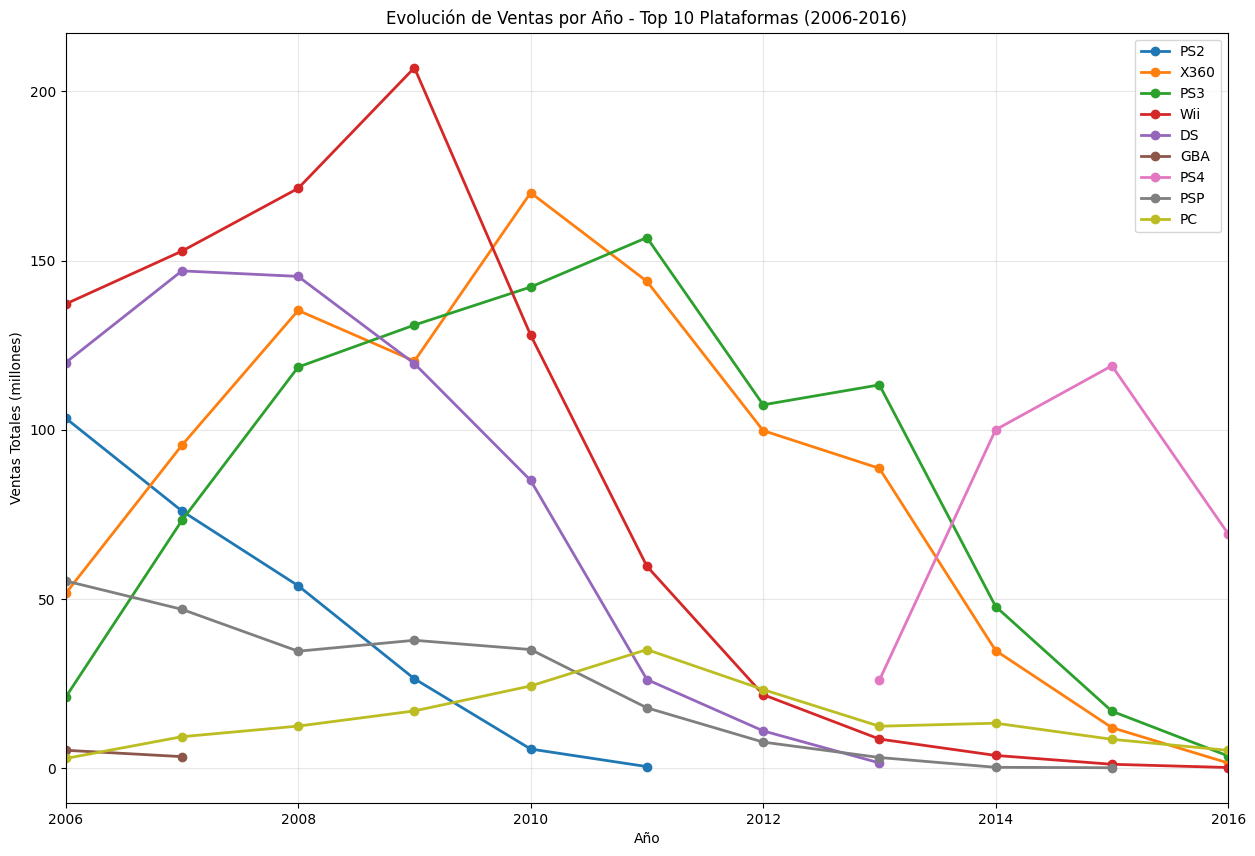

In [39]:
# Filtrar datos desde el año 2006 para evitar inconsistencias
plt.figure(figsize=(15, 10))
# Filtrar la distribución desde 2006
distribucion_desde_2006 = distribucion_año_plataforma.loc[:, 2006:]

for plataforma in nombres_top_plataformas[:10]:  # Top 10 
    ventas_plataforma = distribucion_desde_2006.loc[plataforma]
    ventas_no_cero = ventas_plataforma[ventas_plataforma > 0]
    
    if len(ventas_no_cero) > 0:  # Solo graficar si hay datos
        plt.plot(ventas_no_cero.index, ventas_no_cero.values, 
                marker='o', label=plataforma, linewidth=2)

plt.title('Evolución de Ventas por Año - Top 10 Plataformas (2006-2016)')
plt.xlabel('Año')
plt.ylabel('Ventas Totales (millones)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xlim(2006, 2016)  # Limitar el eje X
plt.show()        

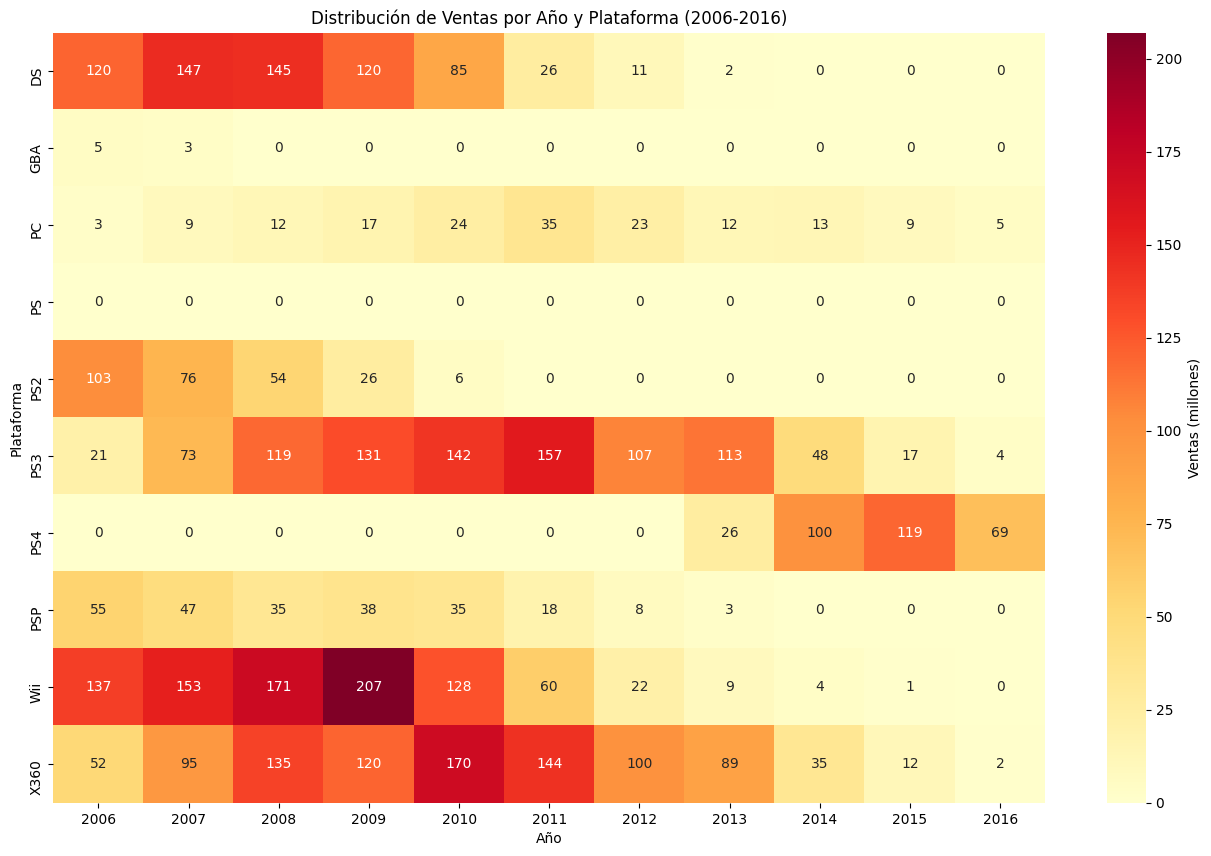

In [40]:
# Mapa de calor para ver todos los patrones desde el 2000
plt.figure(figsize=(16, 10))
sns.heatmap(distribucion_desde_2006, 
            annot=True, 
            fmt='.0f',
            cmap='YlOrRd', 
            cbar_kws={'label': 'Ventas (millones)'})
plt.title('Distribución de Ventas por Año y Plataforma (2006-2016)')
plt.xlabel('Año')
plt.ylabel('Plataforma')
plt.show()

In [42]:
# Encontrar el primer año de aparición de cada plataforma
primera_aparicion = df_games.groupby('platform')['year_of_release'].min().sort_values()

# Filtrar plataformas que aparecieron entre 2010-2014
plataformas_2010_2014 = primera_aparicion[(primera_aparicion >= 2010) & (primera_aparicion <= 2014)]
print("Plataformas que aparecieron entre 2010-2014:")
print(plataformas_2010_2014)

Plataformas que aparecieron entre 2010-2014:
platform
3DS     2011
PSV     2011
WiiU    2012
PS4     2013
XOne    2013
Name: year_of_release, dtype: Int64


In [41]:

# Analizar las ventas recientes de las plataformas
ventas_recientes = df_games[df_games['year_of_release'] >= 2014]
ventas_por_plataforma_reciente = ventas_recientes.groupby('platform')['total_sales'].sum().sort_values(ascending=False)

print("=== VENTAS 2014-2016 POR PLATAFORMA ===")
print(ventas_por_plataforma_reciente.head(10))

=== VENTAS 2014-2016 POR PLATAFORMA ===
platform
PS4     288.15
XOne    140.36
3DS      86.68
PS3      68.18
X360     48.22
WiiU     42.98
PC       27.05
PSV      22.40
Wii       5.07
PSP       0.36
Name: total_sales, dtype: float64


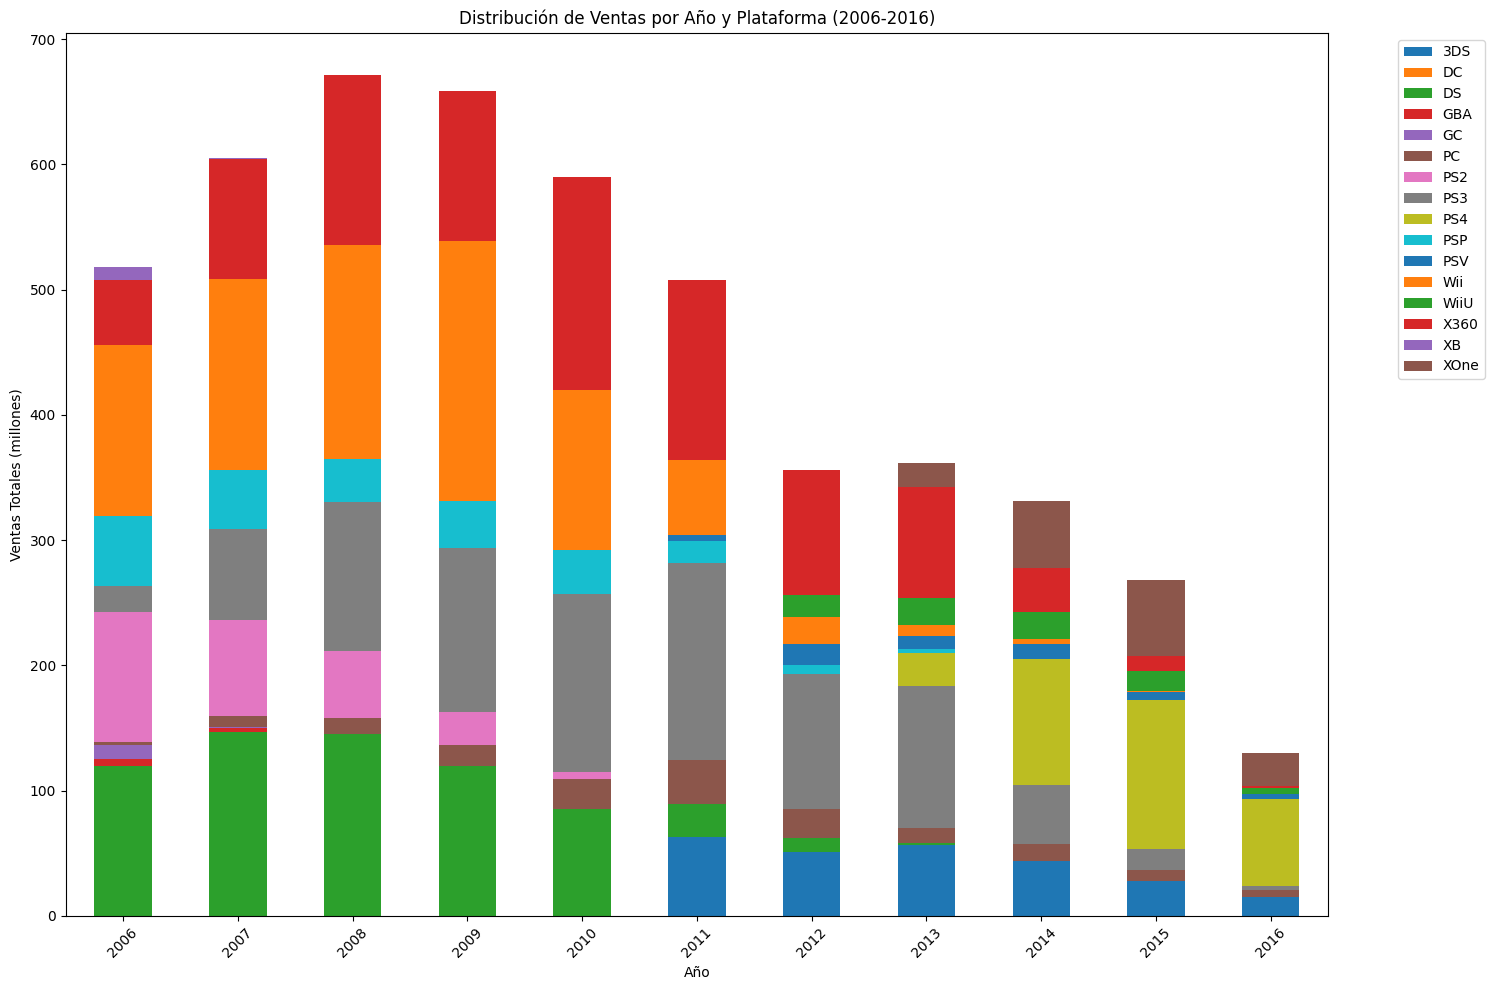

In [42]:
# Filtrar datos 2006-2016
ventas_2006_2016 = df_games[df_games['year_of_release'].between(2006, 2016)]

# Crear gráfico de barras apiladas para 2006-2016
pivot_data_amplio = ventas_2006_2016.groupby(['year_of_release', 'platform'])['total_sales'].sum().unstack(fill_value=0)
pivot_data_amplio.plot(kind='bar', stacked=True, figsize=(15, 10))
plt.title('Distribución de Ventas por Año y Plataforma (2006-2016)')
plt.ylabel('Ventas Totales (millones)')
plt.xlabel('Año')
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


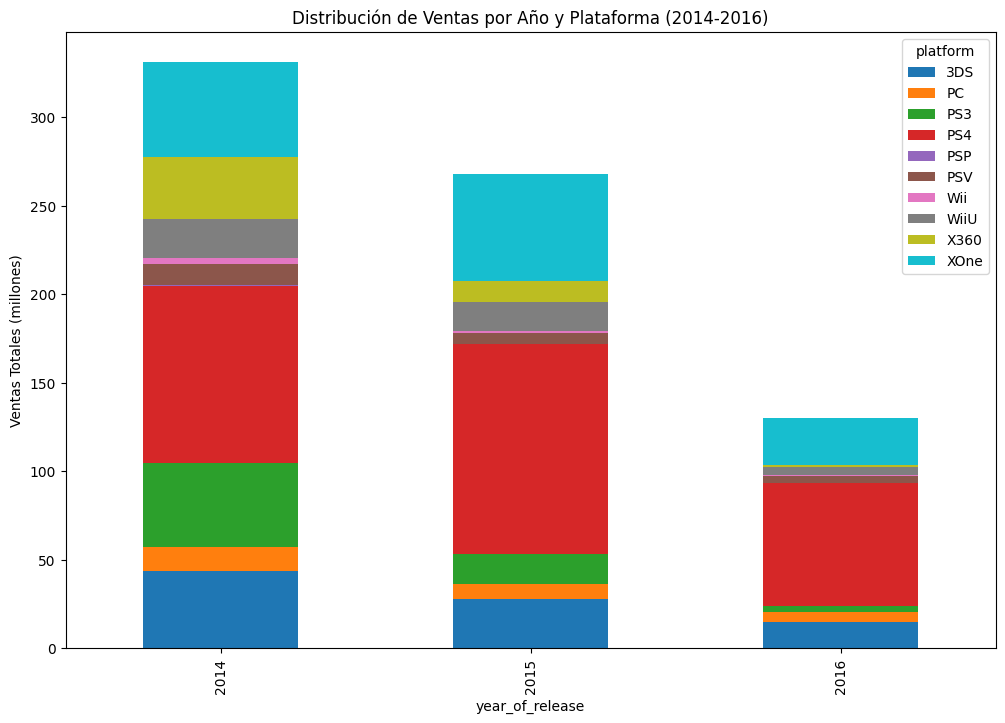

In [43]:
# Crear un gráfico de barras apiladas
ventas_2014_2016 = df_games[df_games['year_of_release'].between(2014, 2016)]
pivot_data = ventas_2014_2016.groupby(['year_of_release', 'platform'])['total_sales'].sum().unstack(fill_value=0)
pivot_data.plot(kind='bar', stacked=True, figsize=(12, 8))
plt.title('Distribución de Ventas por Año y Plataforma (2014-2016)')
plt.ylabel('Ventas Totales (millones)')
plt.show()

- Hasta ahora, con los análisis realizados al momento, observamos que del 2000 al 2006, se lanzaron las plataformas más exitosas basándonos en el volumen de ventas.
- El pico de ventas fue en 2008 con 651.50 M, con consolas de Nintendo a la cabeza.
- Sin embargo para el año 2016, todas las plataformas principales estan en declive y algunas de las que fueron exitosas en 2008 están obsoletas.
- 2013 fue un año pico en los últimos 5 años, con 361.24 M. (2012-2016) 
- En los años 2013-2014 se lanzó una nueva generación de consolas (PS4,XOne)
- PS4 y Xbox One ya llevan de 3-4 años en el mercado (2013-2016).
- El mercado necesita una innovación.
- Para 2017, se debe ofrecer algo genuinamente diferente, por lo que Nintendo debe mantener su presencia en consolas portátiles, ya que ofrece juegos únicos, que no ofrece Sony ni Microsoft, por lo que una nueva consola en 2017 haría labor de competencia a PS4 que es la consola dominante en 2016.

In [44]:
#Crear diagrama de caja de ventas globales por plataforma con datos 2014-2016
datos_relevantes = df_games[df_games['year_of_release'].between(2014, 2016)]
print(f"Juegos en el período 2014-2016: {len(datos_relevantes)}")

# Ver las plataformas con más juegos en este período
plataformas_principales = datos_relevantes['platform'].value_counts().head(8)
print("Plataformas principales 2014-2016:")
print(plataformas_principales)

Juegos en el período 2014-2016: 1689
Plataformas principales 2014-2016:
PS4     376
PSV     295
XOne    228
PS3     219
3DS     212
PC      151
X360    111
WiiU     73
Name: platform, dtype: int64


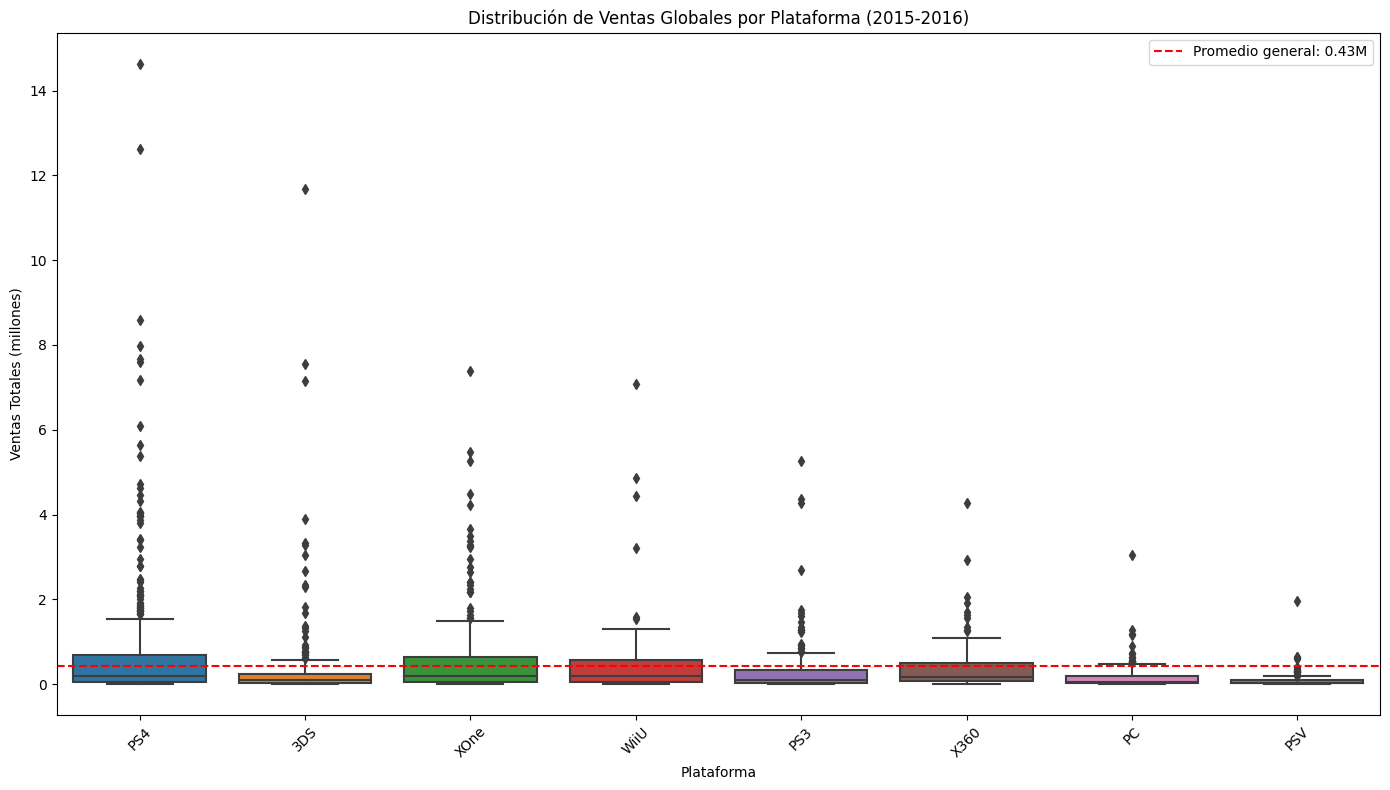

In [45]:
# Filtrar solo las plataformas principales
plataformas_top = plataformas_principales.index.tolist()
datos_filtrados = datos_relevantes[datos_relevantes['platform'].isin(plataformas_top)]
# Crear el boxplot
plt.figure(figsize=(14, 8))
sns.boxplot(data=datos_filtrados, x='platform', y='total_sales')
plt.title('Distribución de Ventas Globales por Plataforma (2015-2016)')
plt.xlabel('Plataforma')
plt.ylabel('Ventas Totales (millones)')
plt.xticks(rotation=45)

# Agregar línea del promedio general
promedio_general = datos_filtrados['total_sales'].mean()
plt.axhline(y=promedio_general, color='red', linestyle='--', 
            label=f'Promedio general: {promedio_general:.2f}M')
plt.legend()
plt.tight_layout()
plt.show()

El gráfico boxplot anterior, nos muestra que PS4 está a la cabeza con más cantidad de juegos con ventas excepcionalmente altas, lo cual indica que PS4 es la plataforma con mas 'hits' en el periodo 2014-2016 en comparación con Xbox One y WiiU con menos outliners.

#### 3.3. Análisis de géneros 
Para éste análisis nos enfocaremos considerando el periodo 2014-2016, ya que es el periodo que marcó el cambio generacional después del segundo pico más alto de ventas en la historia de la tienda.

In [46]:
print("=== ANÁLISIS DE GÉNEROS MÁS RENTABLES (2014-2016) ===")

# Agrupar por género
generos_rentables = datos_relevantes.groupby('genre').agg({
    'total_sales': ['sum', 'count', 'mean']
}).round(2)

# Aplanar nombres de columnas
generos_rentables.columns = ['Total_ventas', 'Numero_juegos', 'Promedio_ventas']

# Ordenar por ventas totales
generos_rentables = generos_rentables.sort_values('Total_ventas', ascending=False)

print("Top géneros por ventas totales:")
display(generos_rentables.head(10))

=== ANÁLISIS DE GÉNEROS MÁS RENTABLES (2014-2016) ===
Top géneros por ventas totales:


,Total_ventas,Numero_juegos,Promedio_ventas
genre,,,
Action,199.36,619,0.32
Shooter,170.94,128,1.34
Sports,109.48,161,0.68
Role-Playing,101.44,221,0.46
Misc,37.55,113,0.33
Fighting,28.22,60,0.47
Racing,27.52,69,0.40
Platform,18.09,38,0.48
Adventure,17.55,185,0.09


El análisis anterior nos dió como resultado un patrón muy interesante:
- El género 'Action' es lider en volumen de ventas así como en cantidad de juegos. 
- El género 'Shooter' está en segundo lugar en volumen de ventas a pesar de que cuenta con una cantidad de juegos 5 veces menor que 'Action' lo cual nos indica que son juegos más exitosos y rentables individualmente.
- El 2017 deberá mantener ambos géneros con estrategias de volumen para 'Action' y de calidad para 'Shooter'.

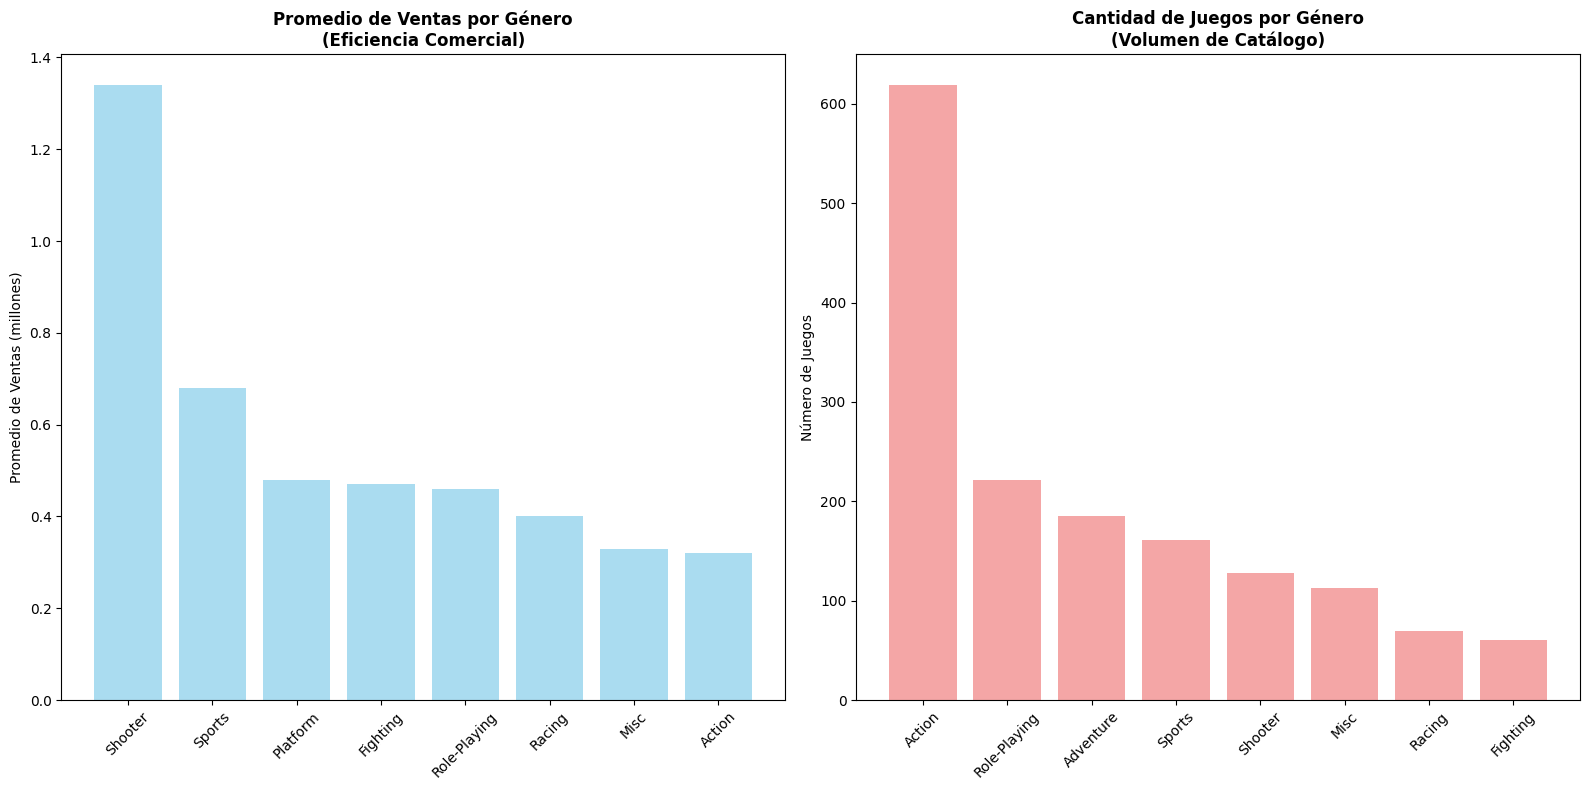

In [47]:
# Crear gráfico para mejor visualizacion
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

# Gráfico 1: Promedio de ventas por género
generos_por_promedio = generos_rentables.sort_values('Promedio_ventas', ascending=False).head(8)
ax1.bar(generos_por_promedio.index, generos_por_promedio['Promedio_ventas'], 
        color='skyblue', alpha=0.7)
ax1.set_title('Promedio de Ventas por Género\n(Eficiencia Comercial)', fontweight='bold')
ax1.set_ylabel('Promedio de Ventas (millones)')
ax1.tick_params(axis='x', rotation=45)

# Gráfico 2: Cantidad de juegos por género
generos_por_cantidad = generos_rentables.sort_values('Numero_juegos', ascending=False).head(8)
ax2.bar(generos_por_cantidad.index, generos_por_cantidad['Numero_juegos'], 
        color='lightcoral', alpha=0.7)
ax2.set_title('Cantidad de Juegos por Género\n(Volumen de Catálogo)', fontweight='bold')
ax2.set_ylabel('Número de Juegos')
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Los gráficos anteriores  nos muestran patrones interesantes, pues observamos que:
- 'Action' lidera en volumen de ventas y en cantidad de juegos.
- 'Shooter' tiene una alta eficiencia comercial, es decir, menos juegos pero altas ventas promedio.

Lo anterior nos da un panorama de que se deberá apostar por estos 2 géneros durante 2017, dado su éxito. Mientras más variedad de títulos se tengan del género 'Action' se asegura que se mantenga el volumen de ventas. Por otro lado los desarrolladores de genero 'shooter', deberán mantener la calidad de los títulos actuales en las nuevas versiones o bien considerar desarrollar expansiones para mas jugabilidad sin perder la escencia. 

#### 3.4. Analisis de reseñas de usuarios y criticos en las plataformas populares
Seleccionamos 7 plataformas para este análisis específico:

- PS4 y XOne por ser las consolas más exitosas de 2014-2016 y nos darán la base para 2017.
- PS3 y X360 al ser las predecesoras de las más exitosas.
- WiiU y 3DS al ser la competencia de Nintendo que ofrece títulos únicos además de que el pico de ventas mas alto se debió a que Nintendo encabezaba la lista con sus consolas tanto portatiles como de sobremesa.
-   PC es la plaforma que ha perdurado desde el inicio (1985) y mantiene presencia hasta la fecha.

In [48]:
#Limpiar y preparar datos para las 7 plataformas.
# Definir las 7 plataformas seleccionadas
plataformas_analisis = ['PS4', 'XOne', 'PS3', 'X360', 'WiiU', '3DS', 'PC']
años_relevantes = [2014, 2015, 2016]
# Filtrar datos para estas plataformas
df_correlacion = df_games[
    (df_games['platform'].isin(plataformas_analisis)) & 
    (df_games['year_of_release'].isin(años_relevantes))].copy()

print(f"Datos filtrados: {len(df_correlacion)} juegos")
print("Distribución por plataforma:")
print(df_correlacion['platform'].value_counts())

Datos filtrados: 1370 juegos
Distribución por plataforma:
PS4     376
XOne    228
PS3     219
3DS     212
PC      151
X360    111
WiiU     73
Name: platform, dtype: int64


In [49]:
# Analizar valores faltantes en las columnas de reseñas
print("=== ANÁLISIS DE VALORES FALTANTES EN RESEÑAS ===")
print(f"Total de juegos en el análisis: {len(df_correlacion)}")
print()

# Analizar critic_score
critic_total = len(df_correlacion)
critic_validos = df_correlacion['critic_score'].notna().sum()
critic_nan = df_correlacion['critic_score'].isna().sum()

print("CRITIC_SCORE:")
print(f"  Valores válidos: {critic_validos} ({(critic_validos/critic_total)*100:.1f}%)")
print(f"  Valores NaN: {critic_nan} ({(critic_nan/critic_total)*100:.1f}%)")
print()

# Analizar user_score
user_total = len(df_correlacion)
user_validos = df_correlacion['user_score'].notna().sum()
user_nan = df_correlacion['user_score'].isna().sum()
user_tbd_originales = df_correlacion['user_score_is_tbd'].sum()

print("USER_SCORE:")
print(f"  Valores válidos: {user_validos} ({(user_validos/user_total)*100:.1f}%)")
print(f"  Valores NaN (total): {user_nan} ({(user_nan/user_total)*100:.1f}%)")
print(f"  De los cuales eran TBD: {user_tbd_originales} ({(user_tbd_originales/user_total)*100:.1f}%)")
print(f"  NaN originales: {user_nan - user_tbd_originales} ({((user_nan - user_tbd_originales)/user_total)*100:.1f}%)")

=== ANÁLISIS DE VALORES FALTANTES EN RESEÑAS ===
Total de juegos en el análisis: 1370

CRITIC_SCORE:
  Valores válidos: 664 (48.5%)
  Valores NaN: 706 (51.5%)

USER_SCORE:
  Valores válidos: 813 (59.3%)
  Valores NaN (total): 557 (40.7%)
  De los cuales eran TBD: 79 (5.8%)
  NaN originales: 478 (34.9%)


Al tener ambas columnas 'critic_score' y 'user_score' con tantos valores NaN, vamos a continuar el análisis sólo con los datos disponibles. Usar la media o la mediana para reemplazar esos NaN podria darnos un resultado muy alterado puesto que en el caso de 'critic_score' tenemos más de la mitad de NaN. Para el caso de 'User_Score' los NaN totales incluyen Datos que antes eran TBD.

In [50]:
# Convertir user_score a numérico 
df_correlacion['user_score_numeric'] = pd.to_numeric(df_correlacion['user_score'], errors='coerce')

# Calcular correlaciones usando solo datos disponibles
print("=== ANÁLISIS DE CORRELACIÓN (SOLO DATOS DISPONIBLES) ===")
print()

# Seleccionar las columnas para correlación
columnas_correlacion = ['critic_score', 'user_score_numeric', 'total_sales']

# Calcular matriz de correlación
correlation_matrix = df_correlacion[columnas_correlacion].corr()

print("Matriz de correlación:")
display(correlation_matrix)

=== ANÁLISIS DE CORRELACIÓN (SOLO DATOS DISPONIBLES) ===

Matriz de correlación:


,critic_score,user_score_numeric,total_sales
critic_score,1.000000,0.518097,0.335183
user_score_numeric,0.518097,1.000000,0.010064
total_sales,0.335183,0.010064,1.000000


In [51]:
# Análisis más detallado de las correlaciones
print("\n=== INTERPRETACIÓN DE CORRELACIONES ===")
print()

# Correlación entre critic_score y total_sales
corr_critic_sales = correlation_matrix.loc['critic_score', 'total_sales']
print(f"Correlación Critic Score vs Ventas: {corr_critic_sales:.3f}")

# Correlación entre user_score y total_sales  
corr_user_sales = correlation_matrix.loc['user_score_numeric', 'total_sales']
print(f"Correlación User Score vs Ventas: {corr_user_sales:.3f}")

# Correlación entre critic_score y user_score
corr_critic_user = correlation_matrix.loc['critic_score', 'user_score_numeric']
print(f"Correlación Critic Score vs User Score: {corr_critic_user:.3f}")


=== INTERPRETACIÓN DE CORRELACIONES ===

Correlación Critic Score vs Ventas: 0.335
Correlación User Score vs Ventas: 0.010
Correlación Critic Score vs User Score: 0.518


##### Interpretación de las correlaciones 

1. CRITIC SCORE vs TOTAL SALES: 0.335
   → Correlación MODERADA y POSITIVA
   → Las reseñas de críticos SÍ influyen en las ventas

2. USER SCORE vs TOTAL SALES: 0.010
   → Correlación MUY DÉBIL (casi inexistente)
   → Las reseñas de usuarios NO predicen las ventas

3. CRITIC SCORE vs USER SCORE: 0.518
   → Correlación MODERADA-FUERTE y POSITIVA
   → Críticos y usuarios tienden a estar de acuerdo



In [52]:
# Analizar por separado los juegos con datos completos vs incompletos
print("=== ANÁLISIS POR DISPONIBILIDAD DE DATOS ===")

# Grupo 1: Juegos con ambas reseñas
ambas_reseñas = df_correlacion.dropna(subset=['critic_score', 'user_score'])
print(f"Juegos con ambas reseñas: {len(ambas_reseñas)} ({len(ambas_reseñas)/len(df_correlacion)*100:.1f}%)")

# Grupo 2: Solo critic_score
solo_critic = df_correlacion.dropna(subset=['critic_score'])
print(f"Juegos con critic_score: {len(solo_critic)} ({len(solo_critic)/len(df_correlacion)*100:.1f}%)")

# Grupo 3: Solo user_score  
solo_user = df_correlacion.dropna(subset=['user_score'])
print(f"Juegos con user_score: {len(solo_user)} ({len(solo_user)/len(df_correlacion)*100:.1f}%)")


=== ANÁLISIS POR DISPONIBILIDAD DE DATOS ===
Juegos con ambas reseñas: 651 (47.5%)
Juegos con critic_score: 664 (48.5%)
Juegos con user_score: 813 (59.3%)


In [53]:
# Analizar juegos SIN critic_score
sin_critic = df_correlacion[df_correlacion['critic_score'].isna()]
con_critic = df_correlacion[df_correlacion['critic_score'].notna()]

print("=== ANÁLISIS DE JUEGOS SIN CRITIC_SCORE ===")
print(f"Juegos SIN critic_score: {len(sin_critic)}")
print(f"Ventas promedio SIN critic_score: {sin_critic['total_sales'].mean():.3f}")
print(f"Ventas promedio CON critic_score: {con_critic['total_sales'].mean():.3f}")

=== ANÁLISIS DE JUEGOS SIN CRITIC_SCORE ===
Juegos SIN critic_score: 706
Ventas promedio SIN critic_score: 0.372
Ventas promedio CON critic_score: 0.661


In [54]:
# Analizar juegos SIN user_score
sin_user = df_correlacion[df_correlacion['user_score_numeric'].isna()]
con_user = df_correlacion[df_correlacion['user_score_numeric'].notna()]

print("=== ANÁLISIS DE JUEGOS SIN USER_SCORE ===")
print(f"Juegos SIN user_score: {len(sin_user)}")
print(f"Ventas promedio SIN user_score: {sin_user['total_sales'].mean():.3f}")
print(f"Ventas promedio CON user_score: {con_user['total_sales'].mean():.3f}")

=== ANÁLISIS DE JUEGOS SIN USER_SCORE ===
Juegos SIN user_score: 557
Ventas promedio SIN user_score: 0.343
Ventas promedio CON user_score: 0.628


Para visualizar mejor esta comparación, se hará un gráfico de barras apiladas.

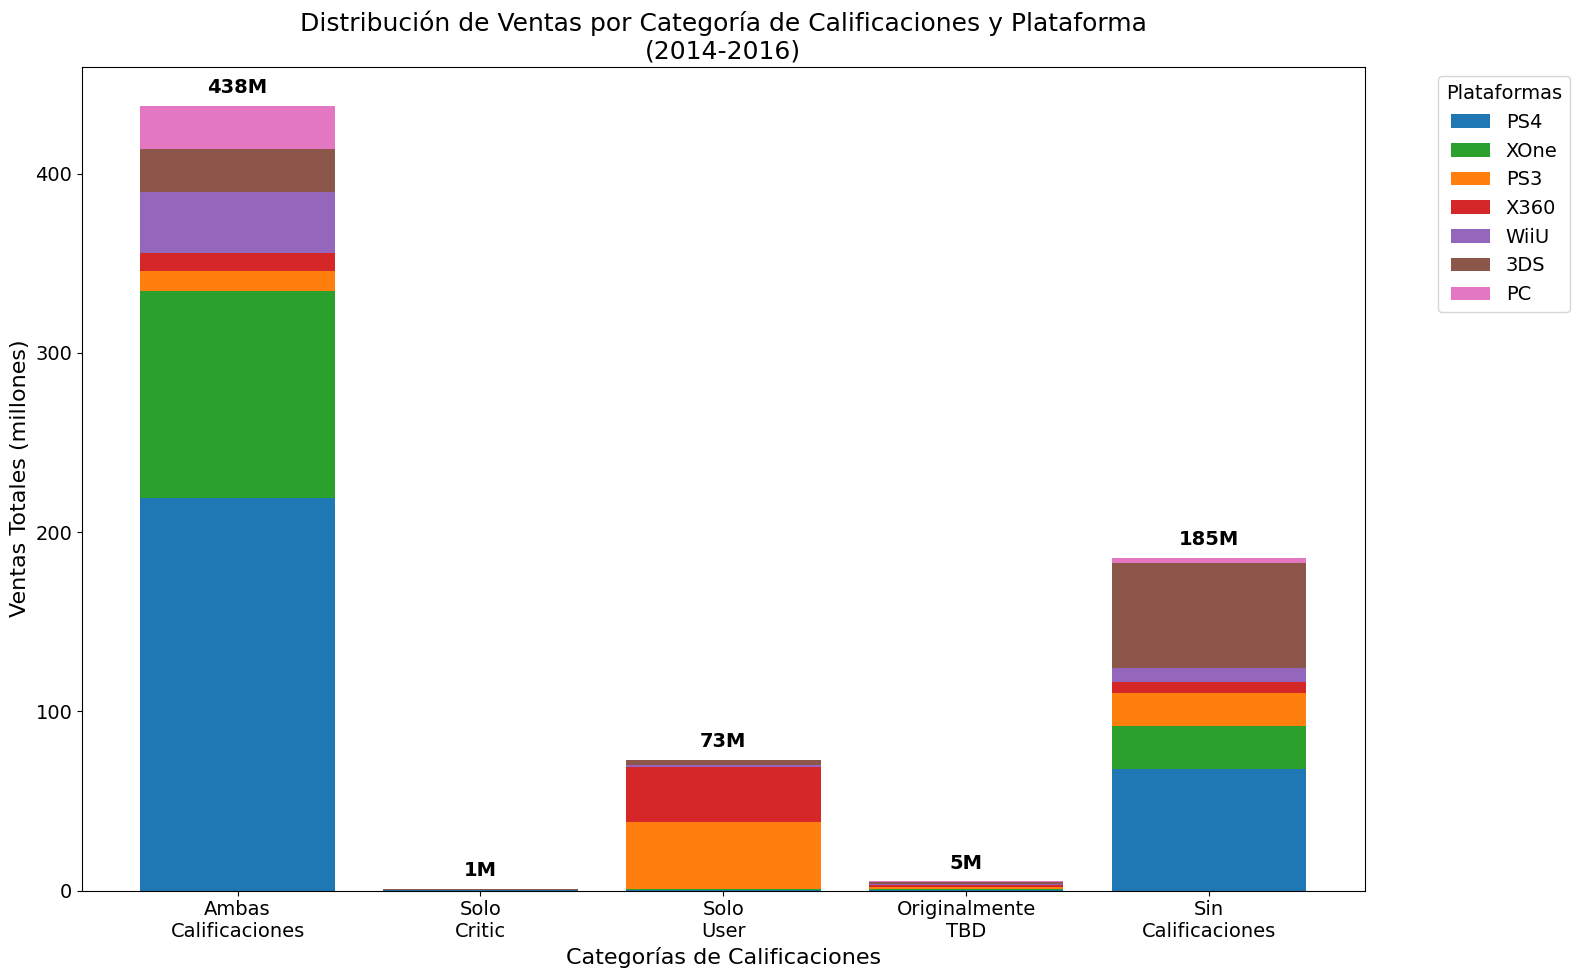

=== RESUMEN DE DATOS POR CATEGORÍA ===
Ambas Calificaciones: 437.8 millones
Solo Critic: 0.9 millones
Solo User: 72.9 millones
Originalmente TBD: 5.2 millones
Sin Calificaciones: 185.5 millones


In [55]:
# Configurar parámetros globales para texto más grande
plt.rcParams.update({
    'font.size': 14,          # Tamaño base de fuente
    'axes.titlesize': 18,     # Título del gráfico
    'axes.labelsize': 16,     # Etiquetas de ejes
    'xtick.labelsize': 14,    # Etiquetas del eje X
    'ytick.labelsize': 14,    # Etiquetas del eje Y
    'legend.fontsize': 14     # Leyenda
})



# Crear categorías más específicas con plataformas
def crear_datos_completos():
    # 1. Juegos con AMBAS calificaciones
    ambas_calificaciones = df_correlacion[
        (df_correlacion['critic_score'].notna()) & 
        (df_correlacion['user_score_numeric'].notna())]

    # 2. Solo critic_score
    solo_critic = df_correlacion[
        (df_correlacion['critic_score'].notna()) & 
        (df_correlacion['user_score_numeric'].isna())]

    # 3. Solo user_score
    solo_user = df_correlacion[
        (df_correlacion['critic_score'].isna()) & 
        (df_correlacion['user_score_numeric'].notna())]

    # 4. Originalmente TBD
    originalmente_tbd = df_correlacion[df_correlacion['user_score_is_tbd'] == True]

    # 5. Sin calificaciones
    sin_calificaciones = df_correlacion[
        (df_correlacion['critic_score'].isna()) & 
        (df_correlacion['user_score_numeric'].isna()) &
        (df_correlacion['user_score_is_tbd'] == False)]

    # Crear DataFrame con todas las combinaciones
    categorias = ['Ambas\nCalificaciones', 'Solo\nCritic', 'Solo\nUser', 'Originalmente\nTBD', 'Sin\nCalificaciones']
    plataformas = ['PS4', 'XOne', 'PS3', 'X360', 'WiiU', '3DS', 'PC']

    # Crear matriz de datos
    datos_matriz = []

    for i, categoria in enumerate([ambas_calificaciones, solo_critic, solo_user, originalmente_tbd, sin_calificaciones]):
        fila = []
        for plataforma in plataformas:
            # CORRECCIÓN: Filtrar por plataforma y sumar ventas
            ventas_plataforma = categoria[categoria['platform'] == plataforma]['total_sales'].sum()
            fila.append(ventas_plataforma)
        datos_matriz.append(fila)

    return np.array(datos_matriz), categorias, plataformas

# Obtener los datos
datos_matriz, categorias, plataformas = crear_datos_completos()

# Crear el gráfico de barras apiladas con colores por plataforma
fig, ax = plt.subplots(figsize=(16, 10))

# Definir colores para cada plataforma
colores_plataformas = {
    'PS4': '#1f77b4',      # Azul
    'XOne': '#2ca02c',     # Verde
    'PS3': '#ff7f0e',      # Naranja
    'X360': '#d62728',     # Rojo
    'WiiU': '#9467bd',     # Púrpura
    '3DS': '#8c564b',      # Marrón
    'PC': '#e377c2'        # Rosa
}

# Crear las barras apiladas
x = np.arange(len(categorias))
width = 0.8
bottom = np.zeros(len(categorias))

# Para cada plataforma, crear una barra apilada
barras = []
for i, plataforma in enumerate(plataformas):
    # Obtener los datos de esta plataforma para todas las categorías
    datos_plataforma = datos_matriz[:, i]
    
    # Crear la barra apilada para esta plataforma
    barra = ax.bar(x, datos_plataforma, width, bottom=bottom, 
                   label=plataforma, color=colores_plataformas[plataforma])
    barras.append(barra)
    
    # Actualizar el bottom para la siguiente plataforma
    bottom += datos_plataforma

# Personalizar el gráfico
ax.set_xlabel('Categorías de Calificaciones')
ax.set_ylabel('Ventas Totales (millones)')
ax.set_title('Distribución de Ventas por Categoría de Calificaciones y Plataforma\n(2014-2016)')
ax.set_xticks(x)
ax.set_xticklabels(categorias)
ax.legend(title='Plataformas', bbox_to_anchor=(1.05, 1), loc='upper left')

# Agregar valores en las barras
for i, categoria in enumerate(categorias):
    total_categoria = datos_matriz[:, :].sum(axis=1)[i]
    ax.text(i, total_categoria + 5, f'{total_categoria:.0f}M', 
            ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# Mostrar resumen de datos
print("=== RESUMEN DE DATOS POR CATEGORÍA ===")
for i, categoria in enumerate(categorias):
    total_ventas = datos_matriz[:, :].sum(axis=1)[i]
    print(f"{categoria.replace(chr(10), ' ')}: {total_ventas:.1f} millones")

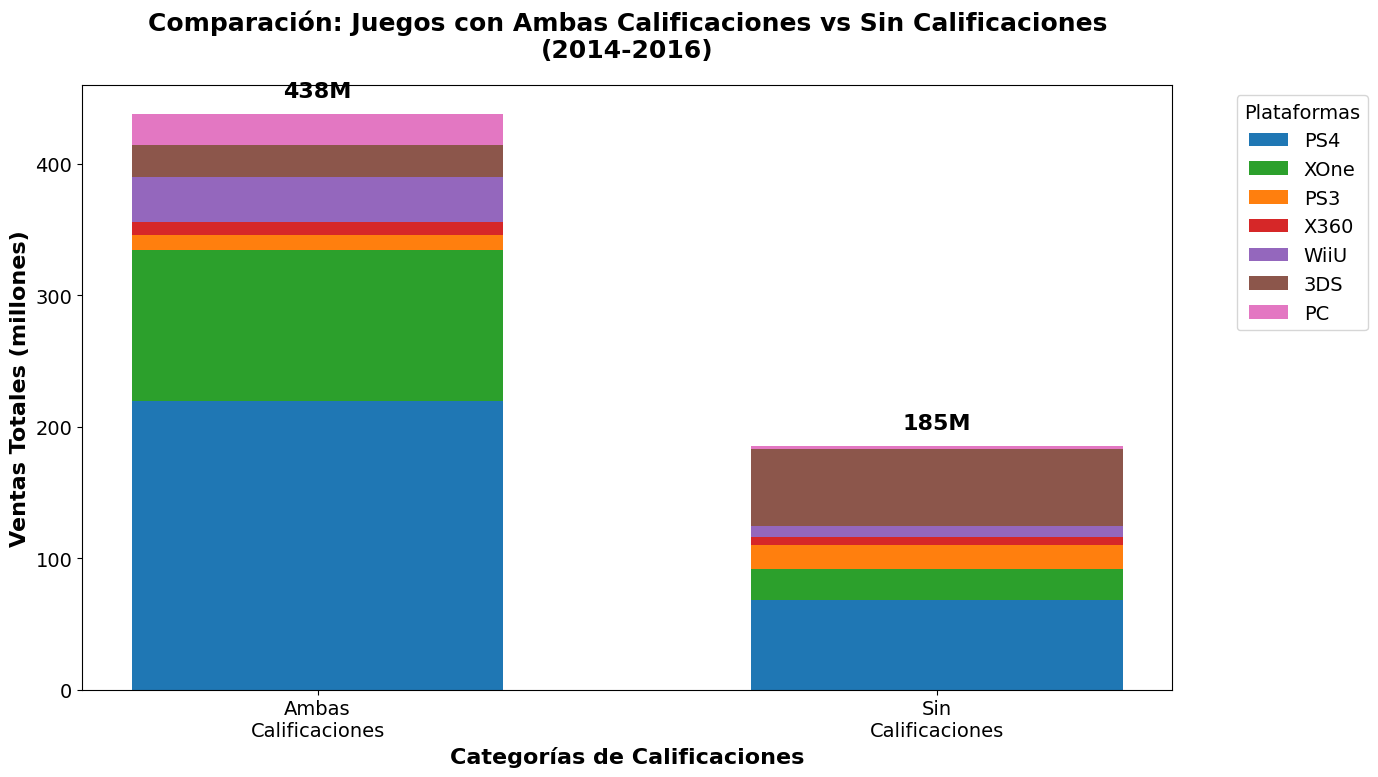

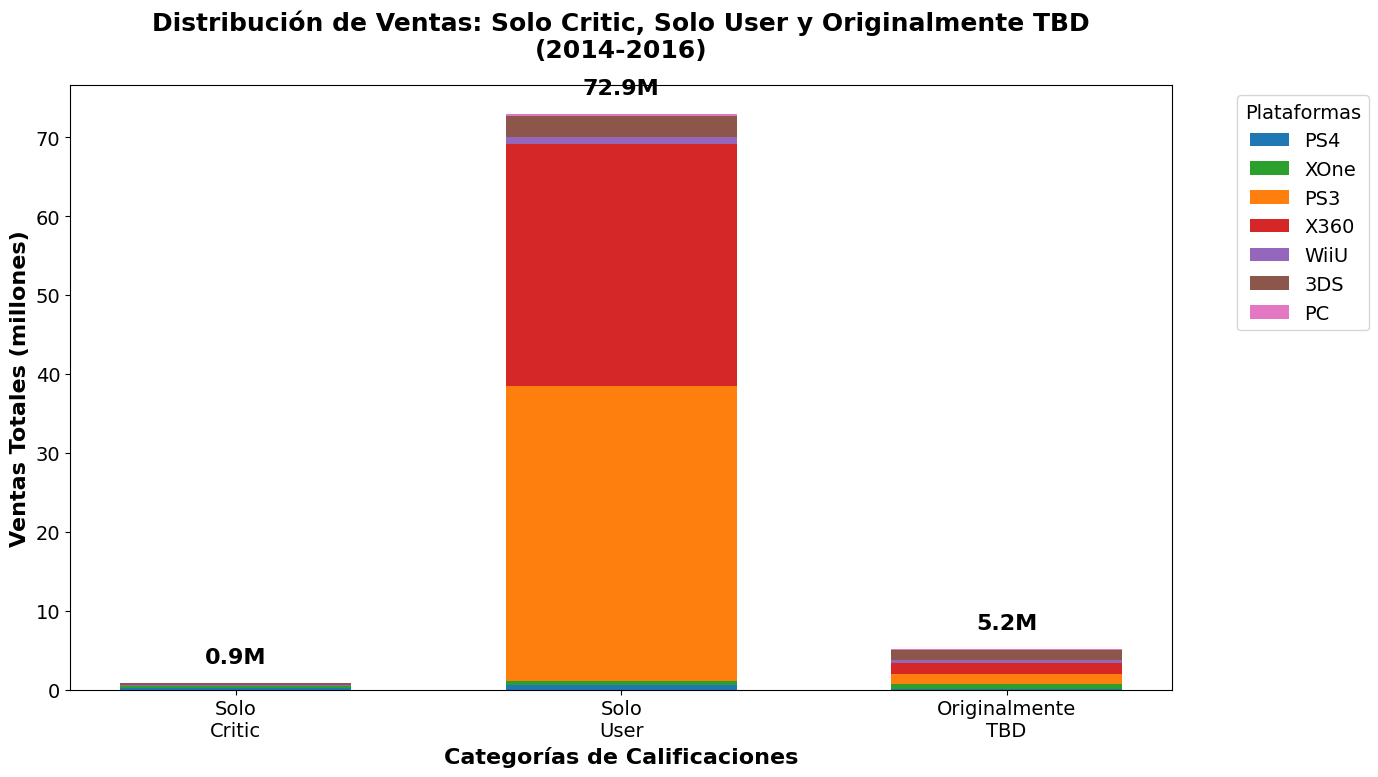

=== ANÁLISIS DE LOS DOS GRÁFICOS ===
GRÁFICO 1 - Comparación principal:
  • Ambas Calificaciones: 438M
  • Sin Calificaciones: 185M
  • Diferencia: 252M

GRÁFICO 2 - Categorías menores:
  • Solo Critic: 0.9M
  • Solo User: 72.9M
  • Originalmente TBD: 5.2M


In [56]:
#Gráfico separado para mejor apreciación

# Obtener los datos 
datos_matriz, categorias, plataformas = crear_datos_completos()

# Definir colores para cada plataforma
colores_plataformas = {
    'PS4': '#1f77b4',      # Azul
    'XOne': '#2ca02c',     # Verde
    'PS3': '#ff7f0e',      # Naranja
    'X360': '#d62728',     # Rojo
    'WiiU': '#9467bd',     # Púrpura
    '3DS': '#8c564b',      # Marrón
    'PC': '#e377c2'        # Rosa
}

# GRÁFICO 1: Ambas Calificaciones vs Sin Calificaciones
fig, ax = plt.subplots(figsize=(14, 8))

# Seleccionar solo las categorías 0 (Ambas) y 4 (Sin Calificaciones)
categorias_graf1 = ['Ambas\nCalificaciones', 'Sin\nCalificaciones']
datos_graf1 = datos_matriz[[0, 4], :]  # Filas 0 y 4

x = np.arange(len(categorias_graf1))
width = 0.6
bottom = np.zeros(len(categorias_graf1))

# Crear barras apiladas para cada plataforma
for i, plataforma in enumerate(plataformas):
    datos_plataforma = datos_graf1[:, i]
    ax.bar(x, datos_plataforma, width, bottom=bottom,
           label=plataforma, color=colores_plataformas[plataforma])
    bottom += datos_plataforma

# Personalizar el gráfico
ax.set_xlabel('Categorías de Calificaciones', fontweight='bold')
ax.set_ylabel('Ventas Totales (millones)', fontweight='bold')
ax.set_title('Comparación: Juegos con Ambas Calificaciones vs Sin Calificaciones\n(2014-2016)', 
             fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(categorias_graf1)
ax.legend(title='Plataformas', bbox_to_anchor=(1.05, 1), loc='upper left')

# Agregar valores totales en las barras
for i, categoria in enumerate(categorias_graf1):
    if i == 0:  # Ambas calificaciones
        total = datos_matriz[0, :].sum()
    else:  # Sin calificaciones
        total = datos_matriz[4, :].sum()
    ax.text(i, total + 10, f'{total:.0f}M',
            ha='center', va='bottom', fontweight='bold', fontsize=16)

plt.tight_layout()
plt.show()

# GRÁFICO 2: Las otras tres categorías
fig, ax = plt.subplots(figsize=(14, 8))

# Seleccionar las categorías 1, 2, 3 (Solo Critic, Solo User, Originalmente TBD)
categorias_graf2 = ['Solo\nCritic', 'Solo\nUser', 'Originalmente\nTBD']
datos_graf2 = datos_matriz[[1, 2, 3], :]  # Filas 1, 2 y 3

x = np.arange(len(categorias_graf2))
width = 0.6
bottom = np.zeros(len(categorias_graf2))

# Crear barras apiladas para cada plataforma
for i, plataforma in enumerate(plataformas):
    datos_plataforma = datos_graf2[:, i]
    ax.bar(x, datos_plataforma, width, bottom=bottom,
           label=plataforma, color=colores_plataformas[plataforma])
    bottom += datos_plataforma

# Personalizar el gráfico
ax.set_xlabel('Categorías de Calificaciones', fontweight='bold')
ax.set_ylabel('Ventas Totales (millones)', fontweight='bold')
ax.set_title('Distribución de Ventas: Solo Critic, Solo User y Originalmente TBD\n(2014-2016)', 
             fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(categorias_graf2)
ax.legend(title='Plataformas', bbox_to_anchor=(1.05, 1), loc='upper left')

# Agregar valores totales en las barras
for i, categoria in enumerate(categorias_graf2):
    if i == 0:  # Solo Critic
        total = datos_matriz[1, :].sum()
    elif i == 1:  # Solo User
        total = datos_matriz[2, :].sum()
    else:  # Originalmente TBD
        total = datos_matriz[3, :].sum()
    ax.text(i, total + 2, f'{total:.1f}M',
            ha='center', va='bottom', fontweight='bold', fontsize=16)

plt.tight_layout()
plt.show()
print("=== ANÁLISIS DE LOS DOS GRÁFICOS ===")
print("GRÁFICO 1 - Comparación principal:")
print(f"  • Ambas Calificaciones: {datos_matriz[0, :].sum():.0f}M")
print(f"  • Sin Calificaciones: {datos_matriz[4, :].sum():.0f}M")
print(f"  • Diferencia: {datos_matriz[0, :].sum() - datos_matriz[4, :].sum():.0f}M")
print()
print("GRÁFICO 2 - Categorías menores:")
print(f"  • Solo Critic: {datos_matriz[1, :].sum():.1f}M")
print(f"  • Solo User: {datos_matriz[2, :].sum():.1f}M") 
print(f"  • Originalmente TBD: {datos_matriz[3, :].sum():.1f}M")

#### Observaciones de análisis de score sobre ventas totales por plataforma
Con el análisis anterior, en el primer gráfico, observamos que los juegos que tienen tanto putuación de usuario como de críticos, son los que mayor volumen de ventas tienen, mientras que los que no cuentan con ambas calificaciones tienen una diferencia de  252 M por debajo de los juegos que cuentan con ambas calificaciones.

El segundo gráfico nos muestra un comparativo entre las ventas totales de los juegos que cuentan solo con calificacion de crítico con 0.9 M muy por debajo de los juegos que cuentan solo con calificación de Usuario, que hacen un total de 72.9 M. Vemos también que los 79 juegos que identificabamos como TBD (To be Determined), son los que originalmente no tenían calificaciones asignadas en la base de datos, posiblemente porque son juegos muy nuevos que aun no cuentan con suficientes reseñas como para poder calificarlo, pero representan ventas pequeñas en comparación de los que cuentan con calificacion asignada por parte del usuario, pero estos son más exitosos que los que cuentan con solo calificacion asignada del crítico. 

En resumen podemos concluir de este análisis que la reseña del usuario influye más en el volumen de ventas, pero ambas reseñas juntas tienen un impacto mucho mayor en el volumen de ventas. 

Para 2017, se deberá enfocar esfuerzos en obtener ambas reseñas en los juegos que se lanzarán al mercado lo más pronto posible para tener un mayor volumen de ventas a lo largo del año.

#### Gráficos de dispersión para consola PS4
Se seleccionó la PS4 para esta representación debido a que es la más exitosa en 2014-2016, pues encabeza el volumen en ventas.


##### Gráfico 2D que muestra correlaciones individuales de 'user_score' y 'critic_score' sobre las ventas totales para PS4.

Juegos de PS4 totales: 392
Juegos de PS4 con reseñas válidas: 249


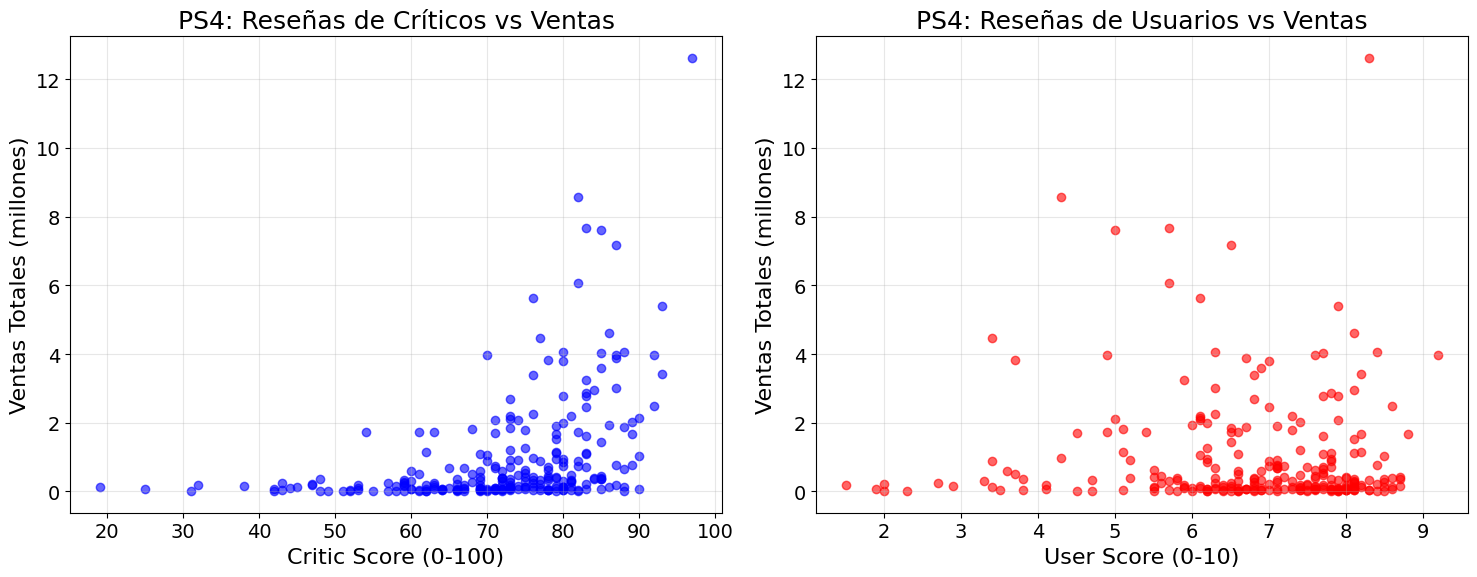


=== CORRELACIONES PARA PS4 ===
Correlación Critic Score vs Ventas: 0.4059
Correlación User Score vs Ventas: -0.0336


In [57]:
# PASO 1: Filtrar datos de PS4 con reseñas válidas
ps4_data = df_games[df_games['platform'] == 'PS4'].copy()

# Filtrar solo juegos con datos de reseñas válidos (sin NaN)
ps4_clean = ps4_data[
    (ps4_data['critic_score'].notna()) & 
    (ps4_data['user_score'].notna())
].copy()

print(f"Juegos de PS4 totales: {len(ps4_data)}")
print(f"Juegos de PS4 con reseñas válidas: {len(ps4_clean)}")

# PASO 2: Convertir user_score a numérico si no está convertido
ps4_clean['user_score_numeric'] = pd.to_numeric(ps4_clean['user_score'], errors='coerce')

# PASO 3: Crear los gráficos de dispersión
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Gráfico 1: Critic Score vs Ventas
ax1.scatter(ps4_clean['critic_score'], ps4_clean['total_sales'], alpha=0.6, color='blue')
ax1.set_xlabel('Critic Score (0-100)')
ax1.set_ylabel('Ventas Totales (millones)')
ax1.set_title('PS4: Reseñas de Críticos vs Ventas')
ax1.grid(True, alpha=0.3)

# Gráfico 2: User Score vs Ventas
ax2.scatter(ps4_clean['user_score_numeric'], ps4_clean['total_sales'], alpha=0.6, color='red')
ax2.set_xlabel('User Score (0-10)')
ax2.set_ylabel('Ventas Totales (millones)')
ax2.set_title('PS4: Reseñas de Usuarios vs Ventas')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# PASO 4: Calcular correlaciones
corr_critic = ps4_clean['critic_score'].corr(ps4_clean['total_sales'])
corr_user = ps4_clean['user_score_numeric'].corr(ps4_clean['total_sales'])

print(f"\n=== CORRELACIONES PARA PS4 ===")
print(f"Correlación Critic Score vs Ventas: {corr_critic:.4f}")
print(f"Correlación User Score vs Ventas: {corr_user:.4f}")

De los gráficos previos, podemos concluir que para PS4 específicamente:

1. Las reseñas de los críticos SI predicen el éxito, ya que 0.4059 es una correlació moderada.
2. Las reseñas de usuarios NO predicen el exito porque -0.03 es casi cero.

Complementando con el análisis general para las 7 plataformas, curiosamente vemos que en ese caso, tener ambas reseñas genera más ventas totales.

##### Gráfico 3D interactivo que nos muestra los 249 con reseñas válidas y las 3 variables en una sola visualización

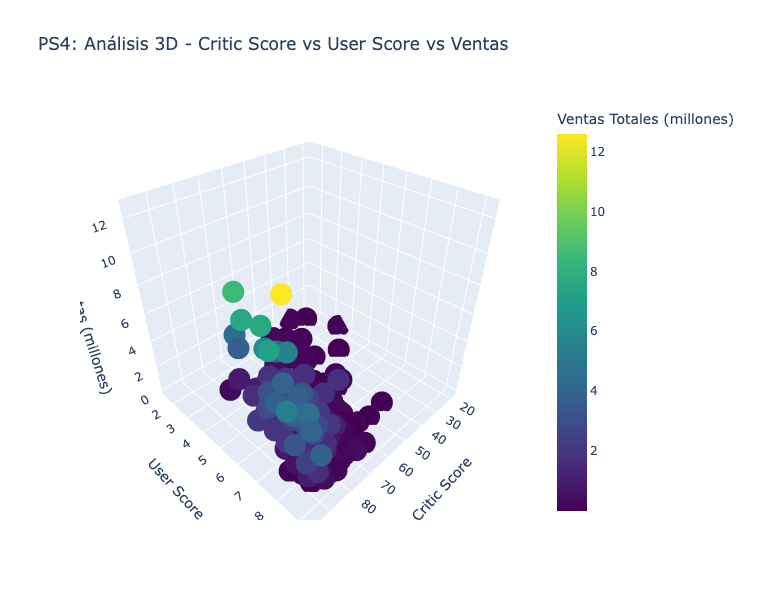

In [58]:
# Crear el gráfico 3D interactivo
fig_3d = px.scatter_3d(
    ps4_clean, 
    x='critic_score', 
    y='user_score_numeric', 
    z='total_sales',
    title='PS4: Análisis 3D - Critic Score vs User Score vs Ventas',
    labels={
        'critic_score': 'Critic Score (0-100)',
        'user_score_numeric': 'User Score (0-10)', 
        'total_sales': 'Ventas Totales (millones)'
    },
    color='total_sales',
    color_continuous_scale='Viridis',
    hover_data=['name']  # Mostrar nombre del juego al pasar el mouse
)

# Personalizar el gráfico
fig_3d.update_layout(
    scene=dict(
        xaxis_title='Critic Score',
        yaxis_title='User Score', 
        zaxis_title='Ventas (millones)'),
    width=800,
    height=600)

fig_3d.show()


#### Análisis de ventas de los mismos videojuegos en diferentes plataformas
Para este análisis primero se van a identificar qué juegos están disponibles en múltiples plataformas y comparar su comportamiento de ventas en cada una, durante el periodo 2014-2016.


In [59]:


# Paso 1: Filtrar datos para 2014-2016
df_periodo = df_games[(df_games['year_of_release'] >= 2014) & 
                      (df_games['year_of_release'] <= 2016)]

print(f"Registros en 2014-2016: {len(df_periodo)}")

# Paso 2: Identificar juegos en múltiples plataformas (solo 2014-2016)
juegos_multiplataforma = df_periodo.groupby('name')['platform'].nunique()

# Filtrar solo los que aparecen en más de una plataforma
juegos_duplicados = juegos_multiplataforma[juegos_multiplataforma > 1]

print(f"\n=== JUEGOS MULTIPLATAFORMA 2014-2016 ===")
print(f"Total de juegos únicos: {len(juegos_multiplataforma)}")
print(f"Juegos en múltiples plataformas: {len(juegos_duplicados)}")
print(f"Porcentaje: {len(juegos_duplicados)/len(juegos_multiplataforma)*100:.1f}%")

print("\nTop 10 juegos con más plataformas:")
print(juegos_duplicados.sort_values(ascending=False).head(10))

Registros en 2014-2016: 1689

=== JUEGOS MULTIPLATAFORMA 2014-2016 ===
Total de juegos únicos: 956
Juegos en múltiples plataformas: 368
Porcentaje: 38.5%

Top 10 juegos con más plataformas:
name
LEGO Jurassic World                  8
FIFA 15                              8
Lego Batman 3: Beyond Gotham         8
LEGO The Hobbit                      8
The LEGO Movie Videogame             8
Skylanders: SuperChargers            7
The Amazing Spider-Man 2 (2014)      7
Skylanders: Trap Team                7
Lego Star Wars: The Force Awakens    7
LEGO Marvel's Avengers               7
Name: platform, dtype: int64


In [60]:
# Analizar la relación entre número de plataformas y ventas totales
analisis_ventas = df_periodo.groupby('name').agg({
    'platform': 'nunique',           # Número de plataformas
    'total_sales': 'sum'             # Ventas totales del juego
}).reset_index()

# Renombrar columnas para claridad
analisis_ventas.columns = ['name', 'num_plataformas', 'ventas_totales']

# Filtrar solo juegos multiplataforma
analisis_ventas = analisis_ventas[analisis_ventas['num_plataformas'] > 1]

print("=== TOP 10 POR NÚMERO DE PLATAFORMAS ===")
top_plataformas = analisis_ventas.sort_values('num_plataformas', ascending=False).head(10)
print(top_plataformas)

print("\n=== TOP 10 POR VENTAS TOTALES ===")
top_ventas = analisis_ventas.sort_values('ventas_totales', ascending=False).head(10)
print(top_ventas)

=== TOP 10 POR NÚMERO DE PLATAFORMAS ===
                                  name  num_plataformas  ventas_totales
432                LEGO Jurassic World                8            4.69
255                            FIFA 15                8           17.37
442       Lego Batman 3: Beyond Gotham                8            4.26
435                    LEGO The Hobbit                8            2.43
816           The LEGO Movie Videogame                8            5.09
724          Skylanders: SuperChargers                7            2.08
801    The Amazing Spider-Man 2 (2014)                7            1.40
725              Skylanders: Trap Team                7            4.30
443  Lego Star Wars: The Force Awakens                7            1.67
433             LEGO Marvel's Avengers                7            2.19

=== TOP 10 POR VENTAS TOTALES ===
                                    name  num_plataformas  ventas_totales
109            Call of Duty: Black Ops 3                5 

In [61]:
# Analizar el top 10 de juegos por ventas totales
print("=== ANÁLISIS DETALLADO DEL TOP 10 POR VENTAS ===")

# Obtener los nombres de los top 10 juegos
nombres_top_juegos = top_ventas['name'].tolist()

# Para cada juego del top 10, mostrar distribución por plataforma
for i, juego in enumerate(nombres_top_juegos, 1):
    print(f"\n{i}. {juego}")
    print("-" * 50)
    
    # Filtrar datos de este juego específico
    datos_juego = df_periodo[df_periodo['name'] == juego]

    # Obtener el género (debería ser el mismo para todas las plataformas)
    genero = datos_juego['genre'].iloc[0]
    
    # Calcular ventas totales del juego
    ventas_totales_juego = datos_juego['total_sales'].sum()
    
    # Mostrar distribución por plataforma
    distribucion = datos_juego.groupby('platform')['total_sales'].sum().sort_values(ascending=False)

    print(f"Género: {genero}")
    print(f"Ventas totales: {ventas_totales_juego:.2f}M")
    print(f"Plataformas: {len(distribucion)}")
    print("\nDistribución por plataforma:")
    
    for plataforma, ventas in distribucion.items():
        porcentaje = (ventas / ventas_totales_juego) * 100
        print(f"  {plataforma}: {ventas:.2f}M ({porcentaje:.1f}%)")

=== ANÁLISIS DETALLADO DEL TOP 10 POR VENTAS ===

1. Call of Duty: Black Ops 3
--------------------------------------------------
Género: Shooter
Ventas totales: 25.67M
Plataformas: 5

Distribución por plataforma:
  PS4: 14.63M (57.0%)
  XOne: 7.39M (28.8%)
  X360: 1.70M (6.6%)
  PS3: 1.69M (6.6%)
  PC: 0.26M (1.0%)

2. Call of Duty: Advanced Warfare
--------------------------------------------------
Género: Shooter
Ventas totales: 21.97M
Plataformas: 5

Distribución por plataforma:
  PS4: 7.66M (34.9%)
  XOne: 5.26M (23.9%)
  PS3: 4.36M (19.8%)
  X360: 4.28M (19.5%)
  PC: 0.41M (1.9%)

3. Grand Theft Auto V
--------------------------------------------------
Género: Action
Ventas totales: 19.26M
Plataformas: 3

Distribución por plataforma:
  PS4: 12.62M (65.5%)
  XOne: 5.47M (28.4%)
  PC: 1.17M (6.1%)

4. FIFA 15
--------------------------------------------------
Género: Sports
Ventas totales: 17.37M
Plataformas: 8

Distribución por plataforma:
  PS4: 6.08M (35.0%)
  PS3: 4.28M (24.6%)

In [62]:
# Filtrar solo el top 10 de juegos multiplataforma por ventas
top_10_nombres = top_ventas['name'].head(10).tolist()
datos_top_10 = df_periodo[df_periodo['name'].isin(top_10_nombres)]

# Crear tabla dinámica del top 10
tabla_top_10 = pd.pivot_table(
    data=datos_top_10,
    values='total_sales',
    index='name',
    columns='platform', 
    aggfunc='sum',
    fill_value=0,
    margins=True,
    margins_name='TOTAL').round(2)

print("=== TABLA DINÁMICA: TOP 10 JUEGOS MULTIPLATAFORMA (2014-2016) ===")
display(tabla_top_10)

=== TABLA DINÁMICA: TOP 10 JUEGOS MULTIPLATAFORMA (2014-2016) ===


platform,3DS,PC,PS3,PS4,PSV,Wii,WiiU,X360,XOne,TOTAL
name,,,,,,,,,,
Call of Duty: Advanced Warfare,0.00,0.41,4.36,7.66,0.00,0.00,0.00,4.28,5.26,21.97
Call of Duty: Black Ops 3,0.00,0.26,1.69,14.63,0.00,0.00,0.00,1.70,7.39,25.67
Destiny,0.00,0.00,1.61,5.64,0.00,0.00,0.00,1.92,3.37,12.54
FIFA 15,0.46,0.29,4.28,6.08,0.60,0.56,0.00,2.92,2.18,17.37
FIFA 16,0.00,0.20,2.70,8.58,0.00,0.00,0.00,1.57,3.25,16.30
Fallout 4,0.00,1.28,0.00,7.17,0.00,0.00,0.00,0.00,4.22,12.67
Grand Theft Auto V,0.00,1.17,0.00,12.62,0.00,0.00,0.00,0.00,5.47,19.26
Minecraft,0.00,0.00,5.27,4.32,1.96,0.00,0.67,0.00,2.76,14.98
Star Wars Battlefront (2015),0.00,0.55,0.00,7.98,0.00,0.00,0.00,0.00,3.66,12.19


<Figure size 1600x1000 with 0 Axes>

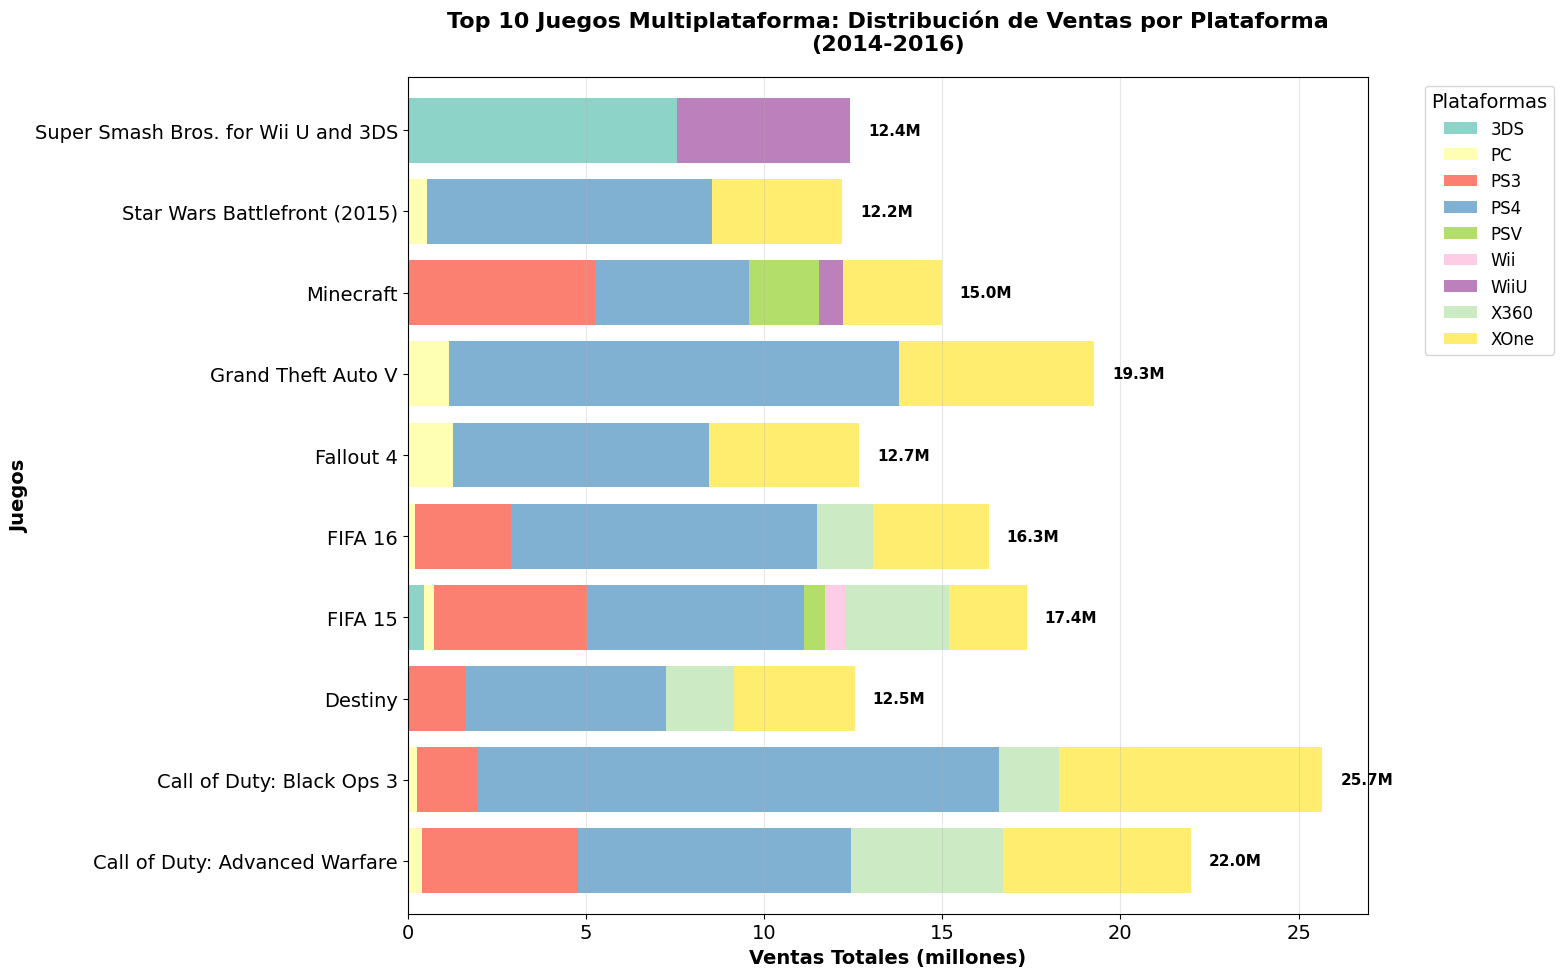

In [63]:

# Crear gráfico de barras apiladas para el top 10 de juegos multiplataforma
plt.figure(figsize=(16, 10))

# Usar los datos de la tabla dinámica (excluyendo la fila y columna TOTAL)
datos_para_grafico = tabla_top_10.iloc[:-1, :-1]  # Excluir última fila y columna

# Crear el gráfico de barras apiladas horizontales
ax = datos_para_grafico.plot(kind='barh', 
                             stacked=True, 
                             figsize=(16, 10),
                             colormap='Set3',  # Paleta de colores distintiva
                             width=0.8)

# Personalizar el gráfico
plt.title('Top 10 Juegos Multiplataforma: Distribución de Ventas por Plataforma\n(2014-2016)', 
          fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Ventas Totales (millones)', fontsize=14, fontweight='bold')
plt.ylabel('Juegos', fontsize=14, fontweight='bold')

# Ajustar la leyenda
plt.legend(title='Plataformas', 
           bbox_to_anchor=(1.05, 1), 
           loc='upper left',
           fontsize=12)

# Agregar valores totales al final de cada barra
for i, (juego, fila) in enumerate(datos_para_grafico.iterrows()):
    total = fila.sum()
    plt.text(total + 0.5, i, f'{total:.1f}M', 
             va='center', ha='left', fontweight='bold', fontsize=11)

# Ajustar el diseño
plt.tight_layout()
plt.grid(axis='x', alpha=0.3)
plt.show()

In [64]:
# Análisis completo de distribución de géneros (todo el dataset)
print("=== DISTRIBUCIÓN GENERAL DE JUEGOS POR GÉNERO ===")

# Agrupar por género para todo el dataset
distribucion_generos = df_games.groupby('genre').agg({
    'total_sales': ['sum', 'count', 'mean', 'median'],
    'name': 'count'
}).round(2)

# Aplanar nombres de columnas
distribucion_generos.columns = ['Total_ventas', 'Numero_juegos', 'Promedio_ventas', 'Mediana_ventas', 'Verificacion_juegos']

# Ordenar por ventas totales
distribucion_generos = distribucion_generos.sort_values('Total_ventas', ascending=False)

print("Distribución completa por género:")
display(distribucion_generos)



=== DISTRIBUCIÓN GENERAL DE JUEGOS POR GÉNERO ===
Distribución completa por género:


,Total_ventas,Numero_juegos,Promedio_ventas,Mediana_ventas,Verificacion_juegos
genre,,,,,
Action,1744.17,3369,0.52,0.19,3369
Sports,1331.27,2348,0.57,0.22,2348
Shooter,1052.45,1323,0.80,0.24,1323
Role-Playing,934.56,1498,0.62,0.18,1498
Platform,827.77,888,0.93,0.27,888
Misc,802.51,1750,0.46,0.16,1750
Racing,728.67,1249,0.58,0.19,1249
Fighting,447.53,849,0.53,0.21,849
Simulation,389.97,873,0.45,0.15,873


La distribución anterior nos muestra los géneros más exitosos en cuanto al volumen de ventas.
Previamente habíamos determinado este análisis exclusivamente para el período 2014-2016, en donde el segundo género más exitoso fue el shooter. 
Sin embargo, en términos generales de todo el data set, mantenemos el genero Action en primer lugar, en segundo lugar Sports y en tercer lugar Shooter. 
Observamos un patrón interesante ya que el genero preferido de todo el historial continua siendo action. Mientras que el genero shooter supera a sports para el periodo 2014-2016.

Recordemos que  en el punto 2.2.4 se encontraron 2 juegos sin género definido. Estos fueron ambos de 1993 y plataforma GEN. Para esta parte del análisis los incluimos debido a que fueron los que menos ventas generaron en la distribución general.


In [65]:
print(df_games['genre'].unique())

# Verificar las ventas de los juegos con género NaN
juegos_nan_genero = df_games[df_games['genre'].isnull()]
ventas_nan_genero = juegos_nan_genero['total_sales'].sum()

print(f"Ventas totales de juegos sin género (NaN): {ventas_nan_genero:.2f} millones")

# Comparar con el análisis de géneros completo incluyendo NaN
distribucion_generos_completa = df_games.groupby('genre', dropna=False).agg({
    'total_sales': ['sum', 'count']
}).round(2)

distribucion_generos_completa.columns = ['Total_ventas', 'Numero_juegos']
distribucion_generos_completa = distribucion_generos_completa.sort_values('Total_ventas', ascending=True)

print("\n=== GÉNEROS ORDENADOS POR MENOR VOLUMEN DE VENTAS (INCLUYENDO NaN) ===")
display(distribucion_generos_completa.head(5))

['Sports' 'Platform' 'Racing' 'Role-Playing' 'Puzzle' 'Misc' 'Shooter'
 'Simulation' 'Action' 'Fighting' 'Adventure' 'Strategy' nan]
Ventas totales de juegos sin género (NaN): 2.42 millones

=== GÉNEROS ORDENADOS POR MENOR VOLUMEN DE VENTAS (INCLUYENDO NaN) ===


,Total_ventas,Numero_juegos
genre,,
NaN,2.42,2
Strategy,174.23,683
Adventure,237.59,1303
Puzzle,242.57,580
Simulation,389.97,873


Concluimos con el análisis anterior que los géneros con menos ventas de la distribución general, con 2.43 M de ventas, son 2 juegos que se lanzaron en 1993 en un género no identificado y con nombre desconocido, para la plataforma GEN. El  segundo lugar con menos ventas son los juegos de estrategia con 174.23 M.

#### 4. PERFILES REGIONALES 
##### 4.1. Perfil de usuario para cada región

In [66]:
print("=== PASO 4: PERFIL DE USUARIO POR REGIÓN ===")
print()

# Análisis de las 5 plataformas principales por región
print("4.1. ANÁLISIS DE PLATAFORMAS PRINCIPALES POR REGIÓN")
print("=" * 60)

# Agrupar ventas por plataforma para cada región
plataformas_na = df_games.groupby('platform')['na_sales'].sum().sort_values(ascending=False)
plataformas_eu = df_games.groupby('platform')['eu_sales'].sum().sort_values(ascending=False)
plataformas_jp = df_games.groupby('platform')['jp_sales'].sum().sort_values(ascending=False)



print("TOP 5 PLATAFORMAS POR REGIÓN DATA SET COMPLETO:")
print()
print("NORTEAMÉRICA (NA):")
print(plataformas_na.head())
print()
print("EUROPA (EU):")
print(plataformas_eu.head())
print()
print("JAPÓN (JP):")
print(plataformas_jp.head())



# Filtrar datos para 2014-2016 específicamente
datos_relevantes = df_games[df_games['year_of_release'].between(2014, 2016)]

# Análisis de plataformas por región (2014-2016)
plataformas_na_2014_2016 = datos_relevantes.groupby('platform')['na_sales'].sum().sort_values(ascending=False)
plataformas_eu_2014_2016 = datos_relevantes.groupby('platform')['eu_sales'].sum().sort_values(ascending=False)
plataformas_jp_2014_2016 = datos_relevantes.groupby('platform')['jp_sales'].sum().sort_values(ascending=False)

print("TOP 5 PLATAFORMAS POR REGIÓN PERIODO 2014-2016:")
print()
print("NORTEAMÉRICA (NA):")
print(plataformas_na_2014_2016.head())
print()
print("EUROPA (EU):")
print(plataformas_eu_2014_2016.head())
print()
print("JAPÓN (JP):")
print(plataformas_jp_2014_2016.head())


=== PASO 4: PERFIL DE USUARIO POR REGIÓN ===

4.1. ANÁLISIS DE PLATAFORMAS PRINCIPALES POR REGIÓN
TOP 5 PLATAFORMAS POR REGIÓN DATA SET COMPLETO:

NORTEAMÉRICA (NA):
platform
X360    602.47
PS2     583.84
Wii     496.90
PS3     393.49
DS      382.40
Name: na_sales, dtype: float64

EUROPA (EU):
platform
PS2     339.29
PS3     330.29
X360    270.76
Wii     262.21
PS      213.61
Name: eu_sales, dtype: float64

JAPÓN (JP):
platform
DS      175.57
PS      139.82
PS2     139.20
SNES    116.55
3DS     100.67
Name: jp_sales, dtype: float64
TOP 5 PLATAFORMAS POR REGIÓN PERIODO 2014-2016:

NORTEAMÉRICA (NA):
platform
PS4     98.61
XOne    81.27
X360    28.30
3DS     22.64
PS3     22.05
Name: na_sales, dtype: float64

EUROPA (EU):
platform
PS4     130.04
XOne     46.25
PS3      25.54
PC       17.97
3DS      16.12
Name: eu_sales, dtype: float64

JAPÓN (JP):
platform
3DS     44.24
PS4     15.02
PSV     14.54
PS3     11.22
WiiU     7.31
Name: jp_sales, dtype: float64


El perfil de usuario que creamos con el análisis previo, nos muestra patrones muy interesantes:

- Plataformas preferidas por región (distribución general del Data Set):
1. NORTEAMÉRICA (NA): X360    602.47 M
2. EUROPA (EU): PS2     339.29 M
3. JAPÓN (JP):  DS      175.57 M

- Plataformas preferidas por región (periodo 2014-2016):
1. NORTEAMÉRICA (NA): PS4     98.61 M
2. EUROPA (EU): PS4     130.04 M
3. JAPÓN (JP):  3DS     44.24 M

En Japón en ambas distribuciones el desarrollador mas popular es Nintendo con su plataforma portatil Nintendo DS, con su versión actual a la cabeza para el periodo 2014-2016 
Para Europa tenemos a la cabeza Sony con su consola Play Station tanto en la distribución general, como en periodo 2014-2016 con su versión  más actual.
Y en Norteamérica, Microsoft con Xbox en la distribución general encabeza la popularidad, mientras que en el periodo 2014-2016 la delantera la lleva Sony con Play Station.



In [67]:




# Filtrar datos 2014-2016
datos_2014_2016 = df_games[df_games['year_of_release'].between(2014, 2016)]

# Calcular ventas totales por región
total_na = datos_2014_2016['na_sales'].sum()
total_eu = datos_2014_2016['eu_sales'].sum()
total_jp = datos_2014_2016['jp_sales'].sum()

print(f"Ventas totales 2014-2016:")
print(f"Norteamérica: {total_na:.2f}M")
print(f"Europa: {total_eu:.2f}M") 
print(f"Japón: {total_jp:.2f}M")

# Calcular cuotas de mercado (top 5 por región)
cuotas_na = (datos_2014_2016.groupby('platform')['na_sales'].sum() / total_na * 100).sort_values(ascending=False).head(5)
cuotas_eu = (datos_2014_2016.groupby('platform')['eu_sales'].sum() / total_eu * 100).sort_values(ascending=False).head(5)
cuotas_jp = (datos_2014_2016.groupby('platform')['jp_sales'].sum() / total_jp * 100).sort_values(ascending=False).head(5)

# Crear tabla dinámica de cuotas de mercado
cuotas_mercado = pd.DataFrame({
    'Norteamérica (%)': cuotas_na,
    'Europa (%)': cuotas_eu,
    'Japón (%)': cuotas_jp
}).fillna(0).round(1)

print("\n=== CUOTAS DE MERCADO POR REGIÓN (2014-2016) ===")
display(cuotas_mercado)

Ventas totales 2014-2016:
Norteamérica: 284.06M
Europa: 270.68M
Japón: 93.09M

=== CUOTAS DE MERCADO POR REGIÓN (2014-2016) ===


,Norteamérica (%),Europa (%),Japón (%)
platform,,,
3DS,8.0,6.0,47.5
PC,0.0,6.6,0.0
PS3,7.8,9.4,12.1
PS4,34.7,48.0,16.1
PSV,0.0,0.0,15.6
WiiU,0.0,0.0,7.9
X360,10.0,0.0,0.0
XOne,28.6,17.1,0.0


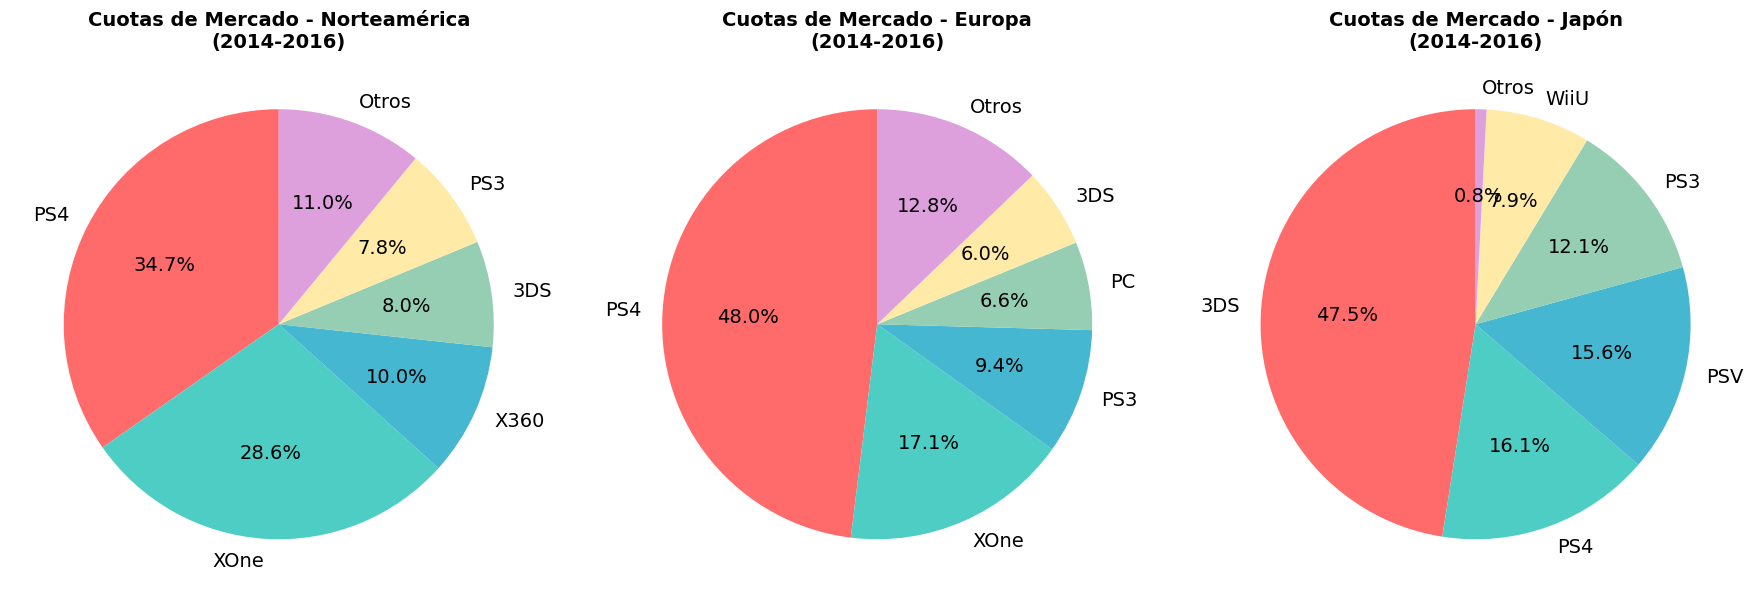

In [68]:
# Crear visualización de cuotas de mercado
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Gráfico de pastel para cada región
regiones = ['Norteamérica', 'Europa', 'Japón']
datos_cuotas = [cuotas_na, cuotas_eu, cuotas_jp]
colores = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7', '#DDA0DD']

for i, (region, cuotas) in enumerate(zip(regiones, datos_cuotas)):
    # Tomar solo top 5 y agrupar el resto como "Otros"
    top_5 = cuotas.head(5)
    otros = 100 - top_5.sum()
    
    if otros > 0:
        labels = list(top_5.index) + ['Otros']
        sizes = list(top_5.values) + [otros]
    else:
        labels = list(top_5.index)
        sizes = list(top_5.values)
    
    axes[i].pie(sizes, labels=labels, autopct='%1.1f%%', 
                colors=colores[:len(sizes)], startangle=90)
    axes[i].set_title(f'Cuotas de Mercado - {region}\n(2014-2016)', 
                      fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()


Y también podemos crear un gráfico de barras comparativo:

<Figure size 1500x800 with 0 Axes>

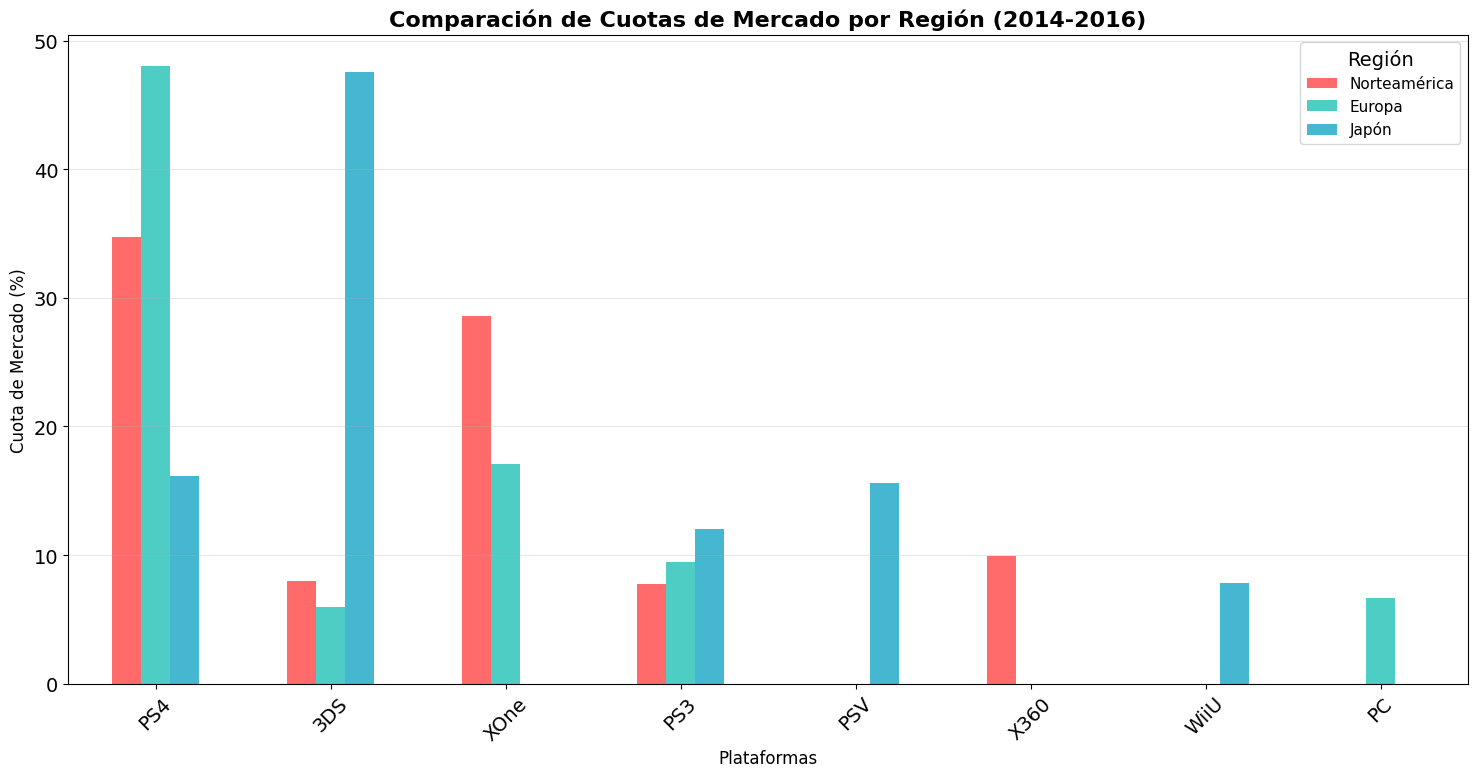

In [69]:


# Gráfico de barras comparativo
plt.figure(figsize=(15, 8))

# Preparar datos para el gráfico de barras
plataformas_todas = set(cuotas_na.index) | set(cuotas_eu.index) | set(cuotas_jp.index)
datos_comparacion = pd.DataFrame({
    'Norteamérica': [cuotas_na.get(plat, 0) for plat in plataformas_todas],
    'Europa': [cuotas_eu.get(plat, 0) for plat in plataformas_todas],
    'Japón': [cuotas_jp.get(plat, 0) for plat in plataformas_todas]}, index=list(plataformas_todas))

# Ordenar por la suma total de cuotas
datos_comparacion['Total'] = datos_comparacion.sum(axis=1)
datos_comparacion = datos_comparacion.sort_values('Total', ascending=False).drop('Total', axis=1)

# Crear gráfico de barras agrupadas
ax = datos_comparacion.head(8).plot(kind='bar', figsize=(15, 8), 
                                   color=['#FF6B6B', '#4ECDC4', '#45B7D1'])
plt.title('Comparación de Cuotas de Mercado por Región (2014-2016)', 
          fontsize=16, fontweight='bold')
plt.xlabel('Plataformas', fontsize=12)
plt.ylabel('Cuota de Mercado (%)', fontsize=12)
plt.legend(title='Región', fontsize=11)
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#### Variaciones observadas:
Japon tiene un dominio de Nintendo.
- Nintendo tiene una fuerte preferencia cultural en Japón.
- La consolas portátiles tienen una mayor aceptación.
- Refleja el estilo de vida japonés (transporte público y espacios reducidos)
Europa y Norteamérica - Dominio de PlayStation.
- PS4 Lidera en ambas regiones.
- Xbox One tiene mejor posición en NA que en Europa.



#### 4. 2 Análisis de los 5 generos principales por región


In [70]:
print("=== ANÁLISIS DE GÉNEROS PRINCIPALES POR REGIÓN ===")
print()

# Análisis de géneros por región (período 2014-2016)
generos_na_2014_2016 = datos_2014_2016.groupby('genre')['na_sales'].sum().sort_values(ascending=False)
generos_eu_2014_2016 = datos_2014_2016.groupby('genre')['eu_sales'].sum().sort_values(ascending=False)
generos_jp_2014_2016 = datos_2014_2016.groupby('genre')['jp_sales'].sum().sort_values(ascending=False)

print("TOP 5 GÉNEROS POR REGIÓN (2014-2016):")
print()
print("NORTEAMÉRICA (NA):")
print(generos_na_2014_2016.head())
print()
print("EUROPA (EU):")
print(generos_eu_2014_2016.head())
print()
print("JAPÓN (JP):")
print(generos_jp_2014_2016.head())
# Calcular cuotas de mercado por género para cada región
cuotas_generos_na = (generos_na_2014_2016 / total_na * 100).head(5)
cuotas_generos_eu = (generos_eu_2014_2016 / total_eu * 100).head(5)
cuotas_generos_jp = (generos_jp_2014_2016 / total_jp * 100).head(5)

# Crear tabla dinámica de cuotas de mercado por género
cuotas_generos = pd.DataFrame({
    'Norteamérica (%)': cuotas_generos_na,
    'Europa (%)': cuotas_generos_eu,
    'Japón (%)': cuotas_generos_jp}).fillna(0).round(1)

print("\n=== CUOTAS DE MERCADO POR GÉNERO Y REGIÓN (2014-2016) ===")
display(cuotas_generos)

=== ANÁLISIS DE GÉNEROS PRINCIPALES POR REGIÓN ===

TOP 5 GÉNEROS POR REGIÓN (2014-2016):

NORTEAMÉRICA (NA):
genre
Shooter         79.02
Action          72.53
Sports          46.13
Role-Playing    33.47
Misc            15.05
Name: na_sales, dtype: float64

EUROPA (EU):
genre
Action          74.68
Shooter         65.52
Sports          45.73
Role-Playing    28.17
Racing          14.13
Name: eu_sales, dtype: float64

JAPÓN (JP):
genre
Role-Playing    31.16
Action          29.58
Fighting         6.37
Misc             5.61
Shooter          4.87
Name: jp_sales, dtype: float64

=== CUOTAS DE MERCADO POR GÉNERO Y REGIÓN (2014-2016) ===


,Norteamérica (%),Europa (%),Japón (%)
genre,,,
Action,25.5,27.6,31.8
Fighting,0.0,0.0,6.8
Misc,5.3,0.0,6.0
Racing,0.0,5.2,0.0
Role-Playing,11.8,10.4,33.5
Shooter,27.8,24.2,5.2
Sports,16.2,16.9,0.0


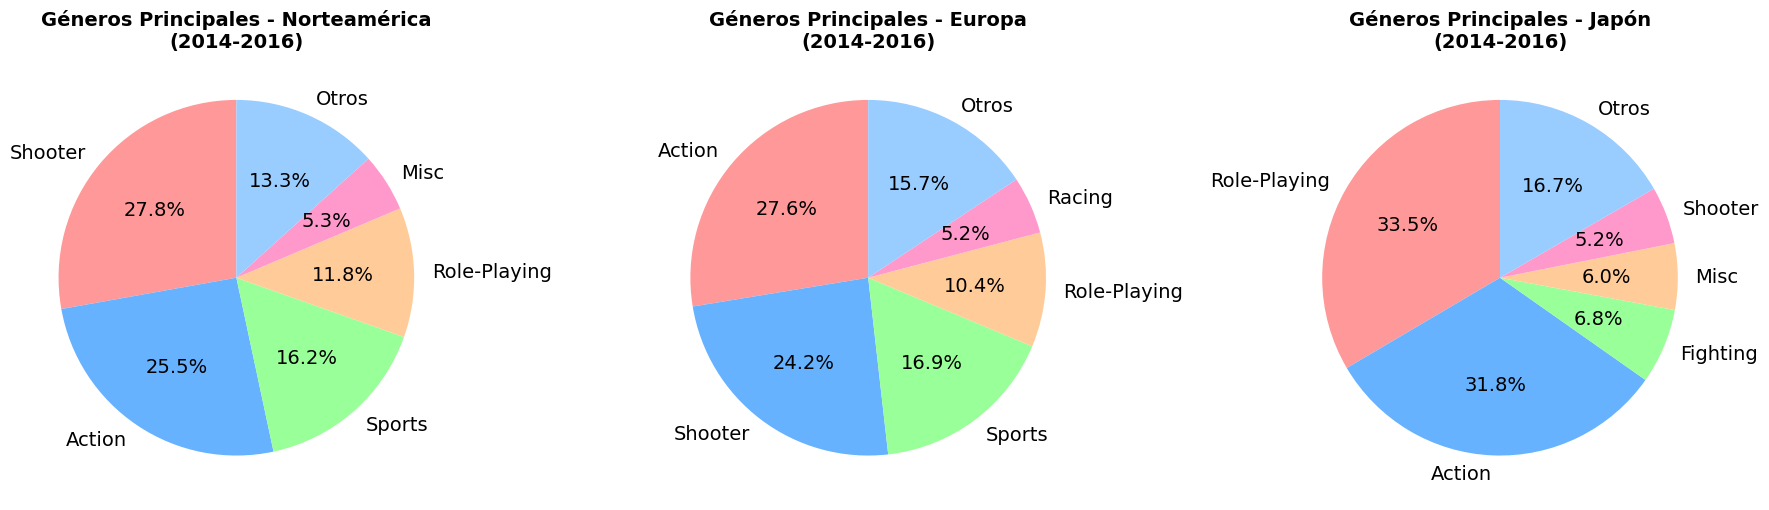

In [71]:
# Visualización de géneros por región
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

regiones = ['Norteamérica', 'Europa', 'Japón']
datos_cuotas_generos = [cuotas_generos_na, cuotas_generos_eu, cuotas_generos_jp]
colores_generos = ['#FF9999', '#66B2FF', '#99FF99', '#FFCC99', '#FF99CC', '#99CCFF']

for i, (region, cuotas) in enumerate(zip(regiones, datos_cuotas_generos)):
    top_5 = cuotas.head(5)
    otros = 100 - top_5.sum()
    
    if otros > 0:
        labels = list(top_5.index) + ['Otros']
        sizes = list(top_5.values) + [otros]
    else:
        labels = list(top_5.index)
        sizes = list(top_5.values)
    
    axes[i].pie(sizes, labels=labels, autopct='%1.1f%%', 
                colors=colores_generos[:len(sizes)], startangle=90)
    axes[i].set_title(f'Géneros Principales - {region}\n(2014-2016)', 
                      fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

Diferencias clave observadas:
Norteamérica:
- Shooter (27.8%) - Domina el mercado
- Action (25.5%) - Segundo lugar
- Preferencia por géneros de acción intensa

Europa:
- Action (27.6%) - Lidera ligeramente
- Shooter (24.2%) - Muy cerca del primero
- Patrones similares a Norteamérica

Japón:
- Role-Playing (33.5%) - Dominio absoluto
- Action (31.8%) - Segundo lugar
- Fighting (6.8%) - Tercer lugar
- Preferencias muy diferentes: RPGs y Fighting

#### 4.3.  Análisis de Calificaciones ESRB

In [72]:
print("=== ANÁLISIS DE CALIFICACIONES ESRB POR REGIÓN (2014-2016) ===")
print()

# Análisis de calificaciones por región
rating_na_2014_2016 = datos_2014_2016.groupby('rating')['na_sales'].sum().sort_values(ascending=False)
rating_eu_2014_2016 = datos_2014_2016.groupby('rating')['eu_sales'].sum().sort_values(ascending=False)
rating_jp_2014_2016 = datos_2014_2016.groupby('rating')['jp_sales'].sum().sort_values(ascending=False)

print("CALIFICACIONES ESRB POR REGIÓN (2014-2016):")
print()
print("NORTEAMÉRICA (NA):")
print(rating_na_2014_2016)
print()
print("EUROPA (EU):")
print(rating_eu_2014_2016)
print()
print("JAPÓN (JP):")
print(rating_jp_2014_2016)

=== ANÁLISIS DE CALIFICACIONES ESRB POR REGIÓN (2014-2016) ===

CALIFICACIONES ESRB POR REGIÓN (2014-2016):

NORTEAMÉRICA (NA):
rating
M       96.42
E       50.74
T       38.95
E10+    33.23
Name: na_sales, dtype: float64

EUROPA (EU):
rating
M       93.44
E       58.06
T       34.07
E10+    26.16
Name: eu_sales, dtype: float64

JAPÓN (JP):
rating
T       14.78
E        8.94
M        8.01
E10+     4.46
Name: jp_sales, dtype: float64


=== CUOTAS DE MERCADO POR CALIFICACIÓN ESRB (2014-2016) ===

NORTEAMÉRICA (%):
rating
M       33.9
E       17.9
T       13.7
E10+    11.7
Name: na_sales, dtype: float64

EUROPA (%):
rating
M       34.5
E       21.4
T       12.6
E10+     9.7
Name: eu_sales, dtype: float64

JAPÓN (%):
rating
T       15.9
E        9.6
M        8.6
E10+     4.8
Name: jp_sales, dtype: float64


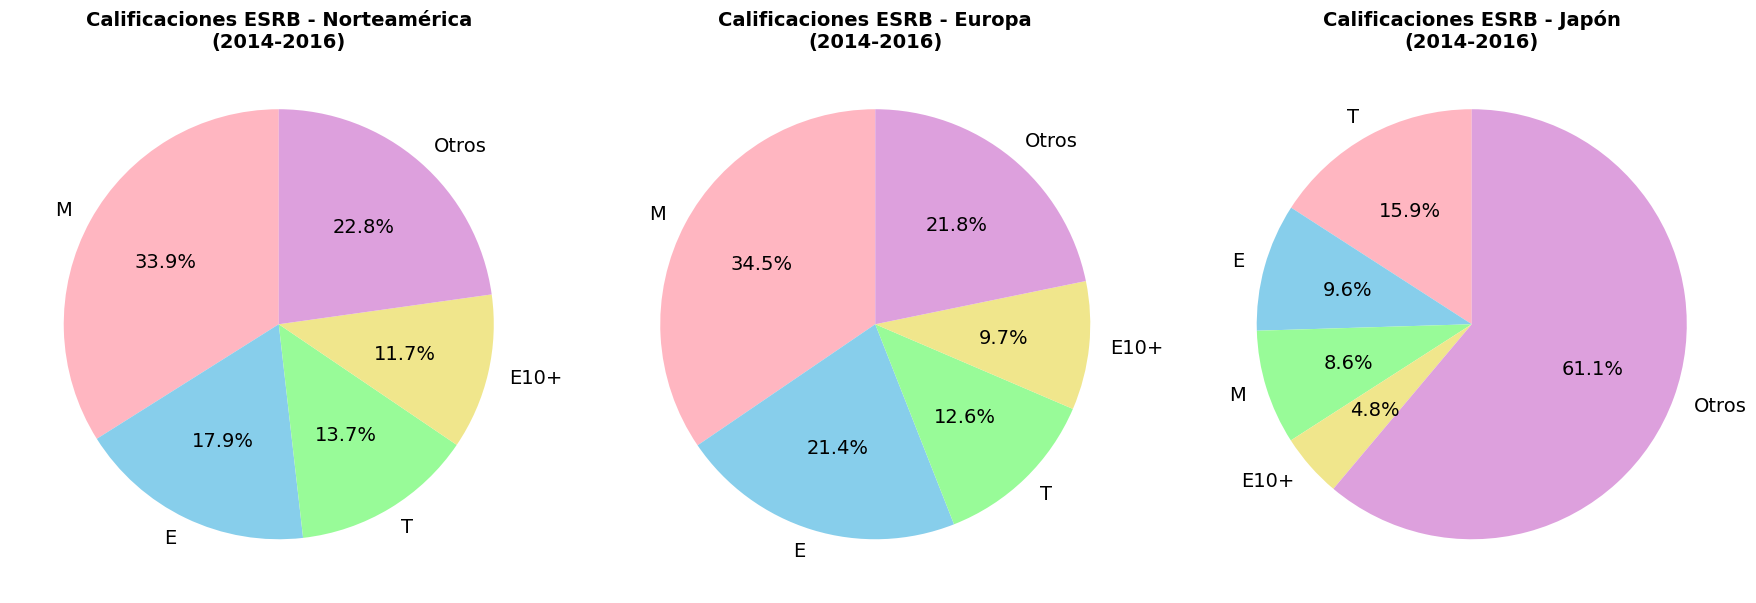

In [73]:
# Calcular cuotas de mercado por calificación ESRB para cada región
cuotas_rating_na = (rating_na_2014_2016 / total_na * 100)
cuotas_rating_eu = (rating_eu_2014_2016 / total_eu * 100)
cuotas_rating_jp = (rating_jp_2014_2016 / total_jp * 100)

print("=== CUOTAS DE MERCADO POR CALIFICACIÓN ESRB (2014-2016) ===")
print()
print("NORTEAMÉRICA (%):")
print(cuotas_rating_na.round(1))
print()
print("EUROPA (%):")
print(cuotas_rating_eu.round(1))
print()
print("JAPÓN (%):")
print(cuotas_rating_jp.round(1))
# Crear visualización de calificaciones ESRB
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

regiones = ['Norteamérica', 'Europa', 'Japón']
datos_cuotas_rating = [cuotas_rating_na, cuotas_rating_eu, cuotas_rating_jp]
colores_rating = ['#FFB6C1', '#87CEEB', '#98FB98', '#F0E68C', '#DDA0DD', '#FFA07A']

for i, (region, cuotas) in enumerate(zip(regiones, datos_cuotas_rating)):
    # Filtrar calificaciones con al menos 1% de cuota
    cuotas_filtradas = cuotas[cuotas >= 1.0]
    otros = 100 - cuotas_filtradas.sum()
    
    if otros > 0:
        labels = list(cuotas_filtradas.index) + ['Otros']
        sizes = list(cuotas_filtradas.values) + [otros]
    else:
        labels = list(cuotas_filtradas.index)
        sizes = list(cuotas_filtradas.values)
    
    axes[i].pie(sizes, labels=labels, autopct='%1.1f%%', 
                colors=colores_rating[:len(sizes)], startangle=90)
    axes[i].set_title(f'Calificaciones ESRB - {region}\n(2014-2016)', 
                      fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

 ##### Conclusiones sobre el Impacto de las Clasificaciones ESRB por Región (2014-2016)
Las diferencias regionales son significativas.
- Norteamérica y Europa tienen ciertas similitudes:
. Dominio de contenido "M" (Mature): 33.9% en NA y 34.5% en EU
. Aceptación de contenido adulto: Ambas regiones muestran alta tolerancia a juegos con clasificación M
. Patrón similar: M > E > T > E10+ en orden de preferencia

- Japón tiene un patrón compeltamente diferente:

. Preferencia por "T" (Teen): 15.9% vs contenido M con solo 8.6%
. Menor aceptación de contenido Mature: Japón muestra resistencia cultural al contenido M
. Mercado más conservador: Prefiere clasificaciones más familiares

Occidente vs Oriente: Hay una clara división cultural en la aceptación de contenido maduro

. Estrategia de localización: Los juegos con clasificación M tendrán mejor recepción en NA/EU que en Japón
. Desarrollo de productos: Para maximizar ventas globales, considerar versiones adaptadas por región

###### En 2017: 
Para NA/EU: Apostar por juegos con clasificación M puede ser muy rentable.
Para Japón: Enfocar en contenido T y E para mayor penetración de mercado.
Estrategia global: Desarrollar juegos que puedan adaptarse a diferentes clasificaciones según la región.

####  5. Puebas de Hipótesis

##### 5.1. Las calificaciones promedio de los usuarios para las plataformas Xbox One y PC son las mismas.
- H₀: Las calificaciones promedio de usuarios son iguales (μ_XOne = μ_PC)
- H₁: Las calificaciones promedio de usuarios son diferentes (μ_XOne ≠ μ_PC)

In [74]:
# Preparar datos para las pruebas de hipótesis
print("=== PREPARACIÓN DE DATOS PARA PRUEBAS DE HIPÓTESIS ===")
print()

# PRUEBA 1: Xbox One vs PC
print("PRUEBA 1: Xbox One vs PC")
print("-" * 30)

# Filtrar datos para Xbox One y PC con user_score válido
xbox_data = df_games[(df_games['platform'] == 'XOne') & 
                     (df_games['user_score'].notna())]
pc_data = df_games[(df_games['platform'] == 'PC') & 
                   (df_games['user_score'].notna())]

print(f"Juegos Xbox One con user_score: {len(xbox_data)}")
print(f"Juegos PC con user_score: {len(pc_data)}")
print(f"Promedio Xbox One: {xbox_data['user_score'].mean():.3f}")
print(f"Promedio PC: {pc_data['user_score'].mean():.3f}")
print(f"Diferencia observada: {pc_data['user_score'].mean() - xbox_data['user_score'].mean():.3f}")

=== PREPARACIÓN DE DATOS PARA PRUEBAS DE HIPÓTESIS ===

PRUEBA 1: Xbox One vs PC
------------------------------
Juegos Xbox One con user_score: 182
Juegos PC con user_score: 770
Promedio Xbox One: 6.521
Promedio PC: 7.062
Diferencia observada: 0.541


In [75]:

print("=== PRUEBA ESTADÍSTICA 1: Xbox One vs PC ===")
print()

# Extraer las calificaciones para cada grupo
xbox_scores = xbox_data['user_score'].dropna()
pc_scores = pc_data['user_score'].dropna()

# Verificar normalidad (opcional pero informativo)
print("Estadísticas descriptivas:")
print(f"Xbox One - Media: {xbox_scores.mean():.3f}, Desv. Est: {xbox_scores.std():.3f}")
print(f"PC - Media: {pc_scores.mean():.3f}, Desv. Est: {pc_scores.std():.3f}")
print()

# Realizar prueba t de dos muestras independientes
# Asumimos varianzas diferentes (Welch's t-test)
t_stat, p_value = st.ttest_ind(xbox_scores, pc_scores, equal_var=False)

print("Resultados de la prueba t:")
print(f"Estadístico t: {t_stat:.4f}")
print(f"Valor p: {p_value:.6f}")
print(f"Nivel de significancia (α): 0.05")
print()

# Interpretación
print("INTERPRETACIÓN:")
if p_value < 0.05:
    print("✅ RECHAZAMOS H₀")
    print("Conclusión: Hay evidencia estadística de que las calificaciones promedio son DIFERENTES")
else:
    print("❌ NO RECHAZAMOS H₀") 
    print("Conclusión: No hay evidencia suficiente para decir que las calificaciones son diferentes")
    

=== PRUEBA ESTADÍSTICA 1: Xbox One vs PC ===

Estadísticas descriptivas:
Xbox One - Media: 6.521, Desv. Est: 1.381
PC - Media: 7.062, Desv. Est: 1.530

Resultados de la prueba t:
Estadístico t: -4.6534
Valor p: 0.000005
Nivel de significancia (α): 0.05

INTERPRETACIÓN:
✅ RECHAZAMOS H₀
Conclusión: Hay evidencia estadística de que las calificaciones promedio son DIFERENTES




La prueba de hipótesis para comparar las calificaciones promedio de usuarios entre Xbox One y PC nos arroja que rechazamos H₀ porque el valor p es mucho menor que alpha (0.05).
También observamos una diferencia práctica entre los promedios de 0.541, lo cual tiene las siguientes implicaciones para el negocio:
1. Los usuarios califican mejor los Juegos de PC que los de Xbox One.
2. Esta diferencia podría indicar que hay un mejor rendimiento en gráficos y en experiencia general en PC.
3. Los desarrolladores podrían necesitar optimizar mejor para Xbox One.
4. PC podría posicionarse como una plataforma fuerte en ciertos títulos.




##### 5.2. Las calificaciones promedio de los usurios para los géneros de Acció y Deportes son diferentees
- H₀: Las calificaciones promedio de usuarios son iguales (μ_Action = μ_Sports)
- H₁: Las calificaciones promedio de usuarios son diferentes (μ_Action ≠ μ_Sports)

In [76]:
print("=== PRUEBA 2: Action vs Sports ===")
print("-" * 40)

# Filtrar datos para géneros Action y Sports con user_score válido
action_data = df_games[(df_games['genre'] == 'Action') & 
                       (df_games['user_score'].notna())]

sports_data = df_games[(df_games['genre'] == 'Sports') & 
                       (df_games['user_score'].notna())]

print(f"Juegos Action con user_score: {len(action_data)}")
print(f"Juegos Sports con user_score: {len(sports_data)}")
print(f"Promedio Action: {action_data['user_score'].mean():.3f}")
print(f"Promedio Sports: {sports_data['user_score'].mean():.3f}")
print(f"Diferencia observada: {action_data['user_score'].mean() - sports_data['user_score'].mean():.3f}")

=== PRUEBA 2: Action vs Sports ===
----------------------------------------
Juegos Action con user_score: 1830
Juegos Sports con user_score: 1103
Promedio Action: 7.054
Promedio Sports: 6.961
Diferencia observada: 0.093


In [78]:
print("=== PRUEBA ESTADÍSTICA 2: Action vs Sports ===")
print()

# Extraer las calificaciones para cada género
action_scores = action_data['user_score'].dropna()
sports_scores = sports_data['user_score'].dropna()

# Estadísticas descriptivas
print("Estadísticas descriptivas:")
print(f"Action - Media: {action_scores.mean():.3f}, Desv. Est: {action_scores.std():.3f}")
print(f"Sports - Media: {sports_scores.mean():.3f}, Desv. Est: {sports_scores.std():.3f}")
print()

# Realizar prueba t de dos muestras independientes
t_stat_2, p_value_2 = st.ttest_ind(action_scores, sports_scores, equal_var=False)

print("Resultados de la prueba t:")
print(f"Estadístico t: {t_stat_2:.4f}")
print(f"Valor p: {p_value_2:.6f}")
print(f"Nivel de significancia (α): 0.05")
print()

# Interpretación
print("INTERPRETACIÓN:")
if p_value_2 < 0.05:
    print("✅ RECHAZAMOS H₀")
    print("Conclusión: Hay evidencia estadística de que las calificaciones promedio son DIFERENTES")
else:
    print("❌ NO RECHAZAMOS H₀")
    print("Conclusión: No hay evidencia suficiente para decir que las calificaciones son diferentes")
    

=== PRUEBA ESTADÍSTICA 2: Action vs Sports ===

Estadísticas descriptivas:
Action - Media: 7.054, Desv. Est: 1.425
Sports - Media: 6.961, Desv. Est: 1.611

Resultados de la prueba t:
Estadístico t: 1.5775
Valor p: 0.114838
Nivel de significancia (α): 0.05

INTERPRETACIÓN:
❌ NO RECHAZAMOS H₀
Conclusión: No hay evidencia suficiente para decir que las calificaciones son diferentes


La prueba de hipótesis para comparar las calificaciones promedio para los géneros Action y Sports nos arroja las siguientes conclusiones:
- La diferencia de 0.093 es muy pequeña.
- Ambos géneros tienen calificaciones spromedio simpilares alrededor de 7.
- El valos p de 0.1148 es mayor a alpha.
- Estadísticamente no hay evidencia suficiente para afirmar que los géneros Action y Sports tienen calificaciones diferentes.
- Los generos Action y Sports son percibidos de manera similar por los usuarios

#### 5.3. Explicación de la formulación de las Hipótesis nula y alternativa.

##### 5.3.1 Para la primera Hipótesis (XOnes vs PC)
Hipótesis Nula: Las calificaciones promedio de los usuarios de XOne y PC son iguales (XOne = PC)
Hipótesis Alternativa: Las calificaciones promedio de los usuarios de XOne y Pc son diferentes ( XOne ≠ PC).

##### 5.3.2. Para la segunda Hipótesis (Action vs Sports)
Hipótesis Nula: Las calificaciones promedio de los usuarios de Action y Sports son iguales ( Action = Sports)
Hipótesis Alternativa: Las calificaciones promedio de los Action y Sports son diferentes ( Action ≠ Sports).

##### 5.3.3. Criterio para probar lás hipótesis.
Se utilizó la prueba t de Student para 2 muestras independientes (Welch's t-test) porque:
- Se compararon las medias de dos grupos independientes.
- Las muestras tienen tamaños diferentes.
- No se asumieron varianzas iguales entre los grupos.
- Los datos son continuos (calificaciones numéricas).
- Se estableció alpha = 0.05 porque es el estandar y proporciona equilibrio entre detectar diferencias reales y evitar falsos positivos.
- El criterio de decisión: Si p-valor < 0.05: Rechazar H₀ (hay evidencia de diferencia significativa)
Si p-valor ≥ 0.05: No rechazar H₀ (no hay evidencia suficiente de diferencia)
- Antes de realizar las pruebas se filtraron solo los registros con calificaciones válidas, es decir, sin NaN. 


#### 6. Conclusiónes generales

#### 1. Tendencias del Mercado de Videojuegos
   ##### Evolución Temporal:
   - El pico histórico de ventas fue en 2008 con 651.50 millones.
   - Período dorado fue 2006-2010 con mayores ventas totales.
   - En 2013 se marcó un segundo pico más alto 361.24 millones, considerando que en esta época se hizo el lanzamiento de una nueva generación.
   - Situación actual de mercado (2016), se aprecia un declive generalizado en todas las plataformas principales.
   - Para 2017, el mercado necesita innovación urgente para revertir la tendencia descendente. Existe también oportunidad para nuevos entrantes al mercado.

#### 2. Plataformas populares y sus ciclos de vida.
   - PS4 se consolidó como plataforma dominante (2014-2016)
   - Los ciclos de vida de las plataformas tienen aproximadamente 8-10 años de vida útil
   - PC es la única plataforma que se ha mantenido presente desde 1985.
   - 5 plataformas desaparecieron completamente en 2016: DS, GBA, PS, PS2, PSP.

#### 3. Géneros preferidos y regionales.
   - Action mantiene el liderazgo histórico y actual (2016)
   - Sports segundo en liderazgo histórico.
   - Shooters supera a Sports para pasar a ser el segundo género en liderazgo en el periodo 2014-2016.
   - El género más popular en Japon es el Role-Playing, mientras que a nivel global ocupa un 8.6%.
   - Para 2017 se deberá enfocar diversidad del género Action.
   - Los desarrolladores de juegos Shooter deberán enfocar la calidad por su alta rentabilidad individual.
     
#### 4. Perfiles Regionales Diferenciados.
   - **Norteamérica**: Preferencia por Shooter (27.8%) y contenido Mature(33.9%) y una trancisión de Xbox 360 a PS4.
   - **Europa**: patrones similares a Norteamérica con Action (27.6%) y Shooter (24.2%) y un dominio histórico y actual de PlayStation.
   - **Japón**: Nintendo mantiene preferencia cultural con plataformas portátiles.

#### 5. Impacto de las reseñas en las Ventas.
   ##### Correlaciones Identificadas:
   - **Critic Score vs Ventas**: 0.335 (moderada influencia)
   - **User Score vs Ventas**: 0.010 (influencia mínima)
   - **Ambas reseñas juntas**: 252M más en ventas que sin reseñas
   La recomendación es priorizar obtener reseñas de críticos y usuarios simultáneamente para maximizar ventas durante 2017.

#### 6. Validación estadística.
   ##### Pruebas de Hipótesis
   - **Prueba 1**: PC tiene calificaciones 0.541 puntos más altas que Xbox One
     Implicación: Los usuarios perciben mejor calidad en juegos de PC.
   - **Prueba 2**: Los géneros Action y Sports son percividos de manera similar por los usuarios.
     

#### 7. Recomendaciones estratégicas para 2017

#####  Recomendaciones por región para 2017
Norteamérica y Europa:
- Priorizar géneros Shooter y Action con clasificación M
- Enfocar en PS4 como plataforma principal

Japón:
- Mantener enfoque en Nintendo y plataformas portátiles
- Priorizar géneros Role-Playing y Fighting
- Contenido familiar (clasificación T y E)

#####  Estrategia de desarrollo para 2017
- Géneros prioritarios: Action (volumen) y Shooter (rentabilidad)
- Plataformas clave: PS4, Xbox One, y mantener presencia en 3DS para Japón
- Calidad sobre cantidad: Asegurar reseñas de críticos y usuarios desde el lanzamiento
  
#####  Indicadores de éxito para monitorear
- Penetración en PS4 (plataforma dominante)
- Recepción de críticos (correlación 0.335 con ventas)
 
#####  Riesgos identificados para 2017
- **Declive generalizado:** Todas las plataformas principales están en declive
- **Saturación del mercado:** Necesidad de diferenciación clara
- **Fragmentación regional:** Estrategias diferentes por región son esenciales

#####  Oportunidades estratégicas
- **Momento de transición:** El mercado está listo para innovación, por lo que una consola nueva de Nintendo que tenga gráficos de alta calidad + portabilidad podría ser la clave.
- **Dominancia de PS4:** Plataforma clara para enfocar recursos en mantener mejora continua para esta consola de Sony.
- **Poder de las reseñas:** Estrategia de marketing enfocada en obtener calificaciones tan pronto sea posible.
